# Comps preparation: the whole project, step by step

This notebook walks through every piece of the project, from PyTorch basics to the final results.
Each part follows the same pattern:

1. **The idea**, in plain words.
2. **By hand.** A small exercise. Work it out on paper, type your answer where it says `None`, and
   run the cell. `check()` tells you if you are right, and shows the answer if you are not.
3. **In code.** The same thing computed by the computer, so you can see the two agree.
4. **The real result**, from the experiments, where there is one.

| Part | Topic | Time |
|---|---|---|
| A | PyTorch in ten minutes: tensors, shapes, matrix products, softmax, gradients, a training loop | 30 min |
| B | Matrix algebra the project uses: products, one-hot, rank, inverse, least squares, re-fitting (with a slow step-by-step head value, B.6b), curvature | 90 min |
| C | Attention from scratch, the valve, and the astrocyte view of softmax | 40 min |
| D | The retrieval task and why it needs exactly R heads | 30 min |
| E | The collateral value of a head | 20 min |
| F | Hemodynamic attenuation in action, with its controls | 30 min (runs about 5 min) |
| G | Backup heads when heads can fail | 15 min |
| H | Induction: a two-layer circuit | 30 min (runs about 3 min) |
| I | Project 3A: transit time and blood pressure | 20 min |
| J | The real results | 15 min |
| K | Questions to expect, with short answers | 30 min |

**Two conventions.** In code, each token is a **row** (PyTorch's habit). In the thesis, each token is
a **column** (weights on the left, data on top, as in the by-hand workbook). They are the same
numbers, transposed. Part B.1 shows this once so it never confuses you again.

Run the setup cell first.

In [1]:
import math, os, sys, glob, pickle, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_printoptions(precision=3, sci_mode=False)
ROOT = os.path.abspath("..")                       # the project folder (this notebook lives in notebooks/)
sys.path.insert(0, os.path.join(ROOT, "src"))

def check(name, yours, answer, tol=1e-2):
    # Compare your by-hand answer with the computed one.
    if yours is None:
        print(f"[ ] {name}: work it out by hand, replace None with your answer, and run again")
        return
    ok = np.allclose(np.asarray(yours, dtype=float), np.asarray(answer, dtype=float), atol=tol, rtol=tol)
    if ok:
        print(f"[RIGHT] {name}")
    else:
        print(f"[NOT YET] {name}: you have {yours}, the answer is {np.round(np.asarray(answer, dtype=float), 4)}")

---
# Part A. PyTorch in ten minutes

## A.1 Tensors and shapes

A tensor is a grid of numbers. Its **shape** says how many numbers along each direction. Almost every
bug in this project is a shape mistake, so get used to printing shapes.

In [2]:
x = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print("x =\n", x)
print("shape:", tuple(x.shape), "  -> 2 rows, 3 columns")
print("first row x[0]:      ", x[0])
print("second column x[:, 1]:", x[:, 1])
print("transpose x.T has shape", tuple(x.T.shape))
print("reshape to (3, 2):\n", x.reshape(3, 2))

x =
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: (2, 3)   -> 2 rows, 3 columns
first row x[0]:       tensor([1., 2., 3.])
second column x[:, 1]: tensor([2., 5.])
transpose x.T has shape (3, 2)
reshape to (3, 2):
 tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])


**By hand.** What is the shape of `x[:, 1:3]` (all rows, columns 1 and 2)? And of `x.T @ x`?

In [3]:
shape_slice = None       # e.g. (2, 2)
shape_xtx = None
check("shape of x[:, 1:3]", shape_slice, tuple(x[:, 1:3].shape))
check("shape of x.T @ x", shape_xtx, tuple((x.T @ x).shape))

[ ] shape of x[:, 1:3]: work it out by hand, replace None with your answer, and run again
[ ] shape of x.T @ x: work it out by hand, replace None with your answer, and run again


## A.2 Broadcasting

When shapes differ, PyTorch stretches a size-1 direction to match. A column (3, 1) plus a row (1, 4)
gives a (3, 4) table. The model uses this to multiply every head by its own valve.

In [4]:
col = torch.tensor([[1.], [2.], [3.]])            # (3, 1)
row = torch.tensor([[10., 20., 30., 40.]])        # (1, 4)
print(col + row)

tensor([[11., 21., 31., 41.],
        [12., 22., 32., 42.],
        [13., 23., 33., 43.]])


In [5]:
entry_2_1 = None         # the entry in row 2, column 1 of col + row (counting from 0)
check("(col + row)[2, 1]", entry_2_1, (col + row)[2, 1])

[ ] (col + row)[2, 1]: work it out by hand, replace None with your answer, and run again


## A.3 Matrix products

`A @ B` multiplies matrices. The rule for shapes: **(a x b) @ (b x c) = (a x c)**. The inner sizes
must match, and they disappear. Entry (i, j) of the result is row i of A dotted with column j of B.

In [6]:
A = torch.tensor([[1., 2.],
                  [3., 4.]])
v = torch.tensor([5., 6.])
print("A @ v =", A @ v)

A @ v = tensor([17., 39.])


**By hand.** Compute `A @ v` (row 1: 1x5 + 2x6, row 2: 3x5 + 4x6). Then: what shape is a
(16 x 32) matrix times a (32 x 8) matrix?

In [7]:
Av = None                # [first, second]
shape_product = None     # (rows, columns)
check("A @ v", Av, A @ v)
check("(16 x 32) @ (32 x 8)", shape_product, (16, 8))

[ ] A @ v: work it out by hand, replace None with your answer, and run again
[ ] (16 x 32) @ (32 x 8): work it out by hand, replace None with your answer, and run again


## A.4 Softmax

Softmax turns any list of scores into weights that are positive and add up to 1:
$a_i = e^{s_i} / \sum_j e^{s_j}$. Attention uses it to decide how much to look at each memory slot.

**By hand.** Scores $(\ln 3, \ln 1)$ give $e^{s} = (3, 1)$, so weights $(3/4, 1/4)$. Now do scores
$(0, 0, \ln 2)$.

In [8]:
print("softmax(ln 3, ln 1) =", torch.softmax(torch.tensor([math.log(3), 0.]), dim=0))
my_softmax = None        # three numbers
check("softmax(0, 0, ln 2)", my_softmax, torch.softmax(torch.tensor([0., 0., math.log(2)]), dim=0))

softmax(ln 3, ln 1) = tensor([0.750, 0.250])
[ ] softmax(0, 0, ln 2): work it out by hand, replace None with your answer, and run again


## A.5 Gradients (autograd)

Training needs the slope of the loss with respect to every weight. PyTorch records each operation and
`backward()` computes all the slopes for you.

For $y = x^2 + 3x$ at $x = 2$, the slope is $2x + 3 = 7$.

In [9]:
x = torch.tensor(2.0, requires_grad=True)
y = x ** 2 + 3 * x
y.backward()                      # fills x.grad with dy/dx
print("dy/dx at x = 2:", x.grad.item())

dy/dx at x = 2: 7.0


In [10]:
my_slope = None                   # by hand: the slope of y = x**3 at x = 2
x = torch.tensor(2.0, requires_grad=True)
(x ** 3).backward()
check("d(x^3)/dx at x = 2", my_slope, x.grad)

[ ] d(x^3)/dx at x = 2: work it out by hand, replace None with your answer, and run again


## A.6 A linear layer

`nn.Linear(4, 3)` holds a weight matrix of shape (3, 4) and a bias of length 3, and computes
$y = x W^\top + b$ for each row $x$. Every $W_Q$, $W_K$, $W_V$, $W_O$ in the project is one of these.

In [11]:
layer = nn.Linear(4, 3)
print("weight shape", tuple(layer.weight.shape), " bias shape", tuple(layer.bias.shape))
batch = torch.randn(10, 4)        # 10 rows, each of length 4
print("output shape", tuple(layer(batch).shape))

weight shape (3, 4)  bias shape (3,)
output shape (10, 3)


In [12]:
n_params = None                   # by hand: how many numbers does nn.Linear(4, 3) learn?
check("parameters in nn.Linear(4, 3)", n_params, sum(p.numel() for p in layer.parameters()))

[ ] parameters in nn.Linear(4, 3): work it out by hand, replace None with your answer, and run again


## A.7 A training loop

Every training loop in the project has the same four lines: **predict, measure the loss, compute the
slopes, take a step.** Here we fit $y = 2x + 1$ from noisy points.

In [13]:
torch.manual_seed(0)
xs = torch.linspace(-1, 1, 50)[:, None]                   # (50, 1)
ys = 2 * xs + 1 + 0.05 * torch.randn_like(xs)             # the truth, plus a little noise
line = nn.Linear(1, 1)
optimizer = torch.optim.SGD(line.parameters(), lr=0.1)
for step in range(300):
    loss = F.mse_loss(line(xs), ys)       # 1. predict and 2. measure the loss
    optimizer.zero_grad()                 #    clear old slopes
    loss.backward()                       # 3. compute the slopes
    optimizer.step()                      # 4. move every weight a little downhill
print(f"learned slope {line.weight.item():.3f} (truth 2), intercept {line.bias.item():.3f} (truth 1), loss {loss.item():.4f}")

learned slope 2.014 (truth 2), intercept 1.002 (truth 1), loss 0.0028


---
# Part B. The matrix algebra the project uses

## B.1 Weights on the left, data on top

In the thesis, each token is a **column** and the weights sit on the left: $Q = W_Q X$. In code each
token is a **row**: `Q = X @ W_Q.T`. These are the same numbers, transposed. To multiply by hand, draw
the L-shape: weights to the left, data on top, and each result entry is the row on its left dotted with
the column above it.

In [14]:
W = torch.tensor([[1., 0., 2.],
                  [0., 1., 1.]])            # 2 x 3 weights (left)
X = torch.tensor([[1., 2.],
                  [0., 1.],
                  [1., 0.]])                # 3 x 2 data: two tokens, one per column (top)
print("thesis convention W @ X =\n", W @ X)
print("code convention, transposed back (X.T @ W.T).T =\n", (X.T @ W.T).T)

thesis convention W @ X =
 tensor([[3., 2.],
        [1., 1.]])
code convention, transposed back (X.T @ W.T).T =
 tensor([[3., 2.],
        [1., 1.]])


In [15]:
entry_0_1 = None         # by hand: row 0 of W dotted with column 1 of X
check("(W @ X)[0, 1]", entry_0_1, (W @ X)[0, 1])

[ ] (W @ X)[0, 1]: work it out by hand, replace None with your answer, and run again


## B.2 A one-hot vector picks out a column

A one-hot vector is all zeros except a single 1. Multiplying a matrix by the one-hot vector for $j$
picks out column $j$. This is how a position label lets attention find a slot.

In [16]:
items = torch.tensor([[1., 2., 3., 4.],
                      [5., 6., 7., 8.]])    # four slots, each item is a column of length 2
e2 = F.one_hot(torch.tensor(2), 4).float()  # [0, 0, 1, 0]
print("items @ e2 =", items @ e2)

items @ e2 = tensor([3., 7.])


In [17]:
pick = None              # by hand: items @ (one-hot for slot 3)
check("items @ e_3", pick, items @ F.one_hot(torch.tensor(3), 4).float())

[ ] items @ e_3: work it out by hand, replace None with your answer, and run again


## B.3 Rank: how many independent equations

The rank of a matrix is the number of truly different rows (or columns). If one row is a combination
of others, it adds no new information. **This is the heart of the counting argument:** each head gives
one equation in the unknown items, and $R$ unknowns need rank $R$, so $R$ different heads.

In [18]:
for M_ in ([[1., 2.], [2., 4.]], [[1., 2.], [3., 4.]]):
    print(M_, "-> rank", torch.linalg.matrix_rank(torch.tensor(M_)).item())

[[1.0, 2.0], [2.0, 4.0]] -> rank 1
[[1.0, 2.0], [3.0, 4.0]] -> rank 2


In [19]:
my_rank = None           # by hand: rank of [[1,0,1],[0,1,1],[1,1,2]]  (hint: look at row 3)
check("rank", my_rank, torch.linalg.matrix_rank(torch.tensor([[1., 0., 1.], [0., 1., 1.], [1., 1., 2.]])))

[ ] rank: work it out by hand, replace None with your answer, and run again


## B.4 Inverting a 2 x 2 matrix and solving equations

$\begin{pmatrix} a & b \\ c & d \end{pmatrix}^{-1} = \frac{1}{ad - bc}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix}$.
To solve $Ax = b$, compute $x = A^{-1} b$. The least-squares re-fit in the project is exactly this, with
bigger matrices.

**By hand.** For $A = \begin{pmatrix} 2 & 1 \\ 1 & 1 \end{pmatrix}$: $ad - bc = 1$, so
$A^{-1} = \begin{pmatrix} 1 & -1 \\ -1 & 2 \end{pmatrix}$. Solve $Ax = (3, 2)$.

In [20]:
A = torch.tensor([[2., 1.], [1., 1.]])
print("A^-1 =\n", torch.linalg.inv(A))
my_x = None              # by hand: x = A^-1 (3, 2)
check("solution of A x = (3, 2)", my_x, torch.linalg.solve(A, torch.tensor([3., 2.])))

A^-1 =
 tensor([[ 1., -1.],
        [-1.,  2.]])
[ ] solution of A x = (3, 2): work it out by hand, replace None with your answer, and run again


## B.5 Least squares, and R squared

Given features $Z$ (one row per example) and targets $y$, the best weights minimise the squared error.
They solve the **normal equations** $Z^\top Z\, w = Z^\top y$, so $w = (Z^\top Z)^{-1} Z^\top y$.

$R^2 = 1 - \dfrac{\text{squared error}}{\text{squared error of predicting the mean}}$: the share of the
variation the fit explains. **"Solved" in the thesis means $R^2 \ge 0.98$.**

**By hand.** Fit $y = a + b\,x$ through $(0, 1), (1, 2), (2, 4)$.
$Z = \begin{pmatrix}1&0\\1&1\\1&2\end{pmatrix}$, $Z^\top Z = \begin{pmatrix}3&3\\3&5\end{pmatrix}$,
$Z^\top y = (7, 10)$. Use B.4 to solve for $(a, b)$, then compute $R^2$.

In [21]:
Z = torch.tensor([[1., 0.], [1., 1.], [1., 2.]])
y = torch.tensor([1., 2., 4.])
w = torch.linalg.solve(Z.T @ Z, Z.T @ y)
pred = Z @ w
r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print("a, b =", w, "  predictions", pred, "  R^2 =", round(r2.item(), 4))

a, b = tensor([0.833, 1.500])   predictions tensor([0.833, 2.333, 3.833])   R^2 = 0.9643


In [22]:
my_b = None              # the slope b
my_r2 = None             # R^2
check("slope b", my_b, w[1])
check("R^2", my_r2, r2)

[ ] slope b: work it out by hand, replace None with your answer, and run again
[ ] R^2: work it out by hand, replace None with your answer, and run again


## B.6 Removing a feature, with and without re-fitting

This is the collateral value in miniature. Two features are **copies** of each other, and the target
is one of them. With both, the fit can use weights (0.5, 0.5).

* Remove one **without re-fitting**: the output halves, so the loss rises. Both look important.
* Remove one **with re-fitting**: the other takes weight 1, and the loss does not change. The copy is
  worth nothing.

**By hand.** If $z_1$ has variance 1 and the weights are (0.5, 0.5), what is the loss after removing
$z_2$ without re-fitting? (The output is $0.5 z_1$ instead of $z_1$.)

In [23]:
torch.manual_seed(0)
n = 10000
z1 = torch.randn(n, 1, dtype=torch.double)
Zc = torch.cat([z1, z1], 1)                          # two identical features
t = z1.clone()                                       # the target is z1
w_both = torch.linalg.lstsq(Zc, t, driver="gelsd").solution   # the smallest weights that fit: (0.5, 0.5)
mse = lambda pred: ((pred - t) ** 2).mean().item()
print("weights with both:", w_both.flatten())
print("loss with both:            ", round(mse(Zc @ w_both), 4))
print("remove z2, no re-fit:      ", round(mse(Zc[:, :1] * w_both[0]), 4))
w_one = torch.linalg.lstsq(Zc[:, :1], t).solution
print("remove z2, re-fit z1 alone:", round(mse(Zc[:, :1] @ w_one), 4))

weights with both: tensor([0.500, 0.500], dtype=torch.float64)
loss with both:             0.0
remove z2, no re-fit:       0.2537
remove z2, re-fit z1 alone: 0.0


In [24]:
no_refit_loss = None
check("loss after removing a copy without re-fitting", no_refit_loss, mse(Zc[:, :1] * w_both[0]), tol=0.02)

[ ] loss after removing a copy without re-fitting: work it out by hand, replace None with your answer, and run again


## B.6b Valuing a head slowly: one example, every step

B.7 gives a formula for a head's value. This section builds it from nothing, on numbers small enough
to do on paper. The question is always the same:

> **If we remove head 2 and let the other heads adjust as well as they can, how much worse does the
> best prediction get?**

The example has two heads, each giving one number per token, and three tokens. First, three small tools.

### Tool 1: dot product and squared length

The dot product of two vectors multiplies them entry by entry and adds: $(1,1,0)\cdot(1,0,1) = 1 + 0 + 0 = 1$.
A vector dotted with itself is its **squared length**: $(1,0,1)\cdot(1,0,1) = 2$.

**By hand.** $(1,1,0)\cdot(3,2,1)$ and $(1,0,1)\cdot(1,0,1)$.

In [25]:
head1 = torch.tensor([1., 1., 0.], dtype=torch.double)
head2 = torch.tensor([1., 0., 1.], dtype=torch.double)
y     = torch.tensor([3., 2., 1.], dtype=torch.double)
my_dot = None            # head1 . y
my_len2 = None           # head2 . head2
check("head1 . y", my_dot, head1 @ y)
check("head2 . head2", my_len2, head2 @ head2)

[ ] head1 . y: work it out by hand, replace None with your answer, and run again
[ ] head2 . head2: work it out by hand, replace None with your answer, and run again


### Tool 2: the best weight when you may use only one feature

If you must predict $y$ from one feature $z$ alone, the best weight is

$$w = \frac{z \cdot y}{z \cdot z}.$$

This is B.5 with a single column: $Z^\top Z$ is just the number $z\cdot z$, so "invert" means "divide".

**By hand.** The best weight on head 1 alone, to predict $y = (3, 2, 1)$.

In [26]:
w_alone = (head1 @ y) / (head1 @ head1)
my_w = None              # (head1 . y) / (head1 . head1)
check("best weight on head 1 alone", my_w, w_alone)

[ ] best weight on head 1 alone: work it out by hand, replace None with your answer, and run again


### Tool 3: the leftover, the part another vector cannot copy

How much of head 2 "looks like" head 1? By Tool 2, the best copy of head 2 made from head 1 is
$\frac{\text{head1}\cdot\text{head2}}{\text{head1}\cdot\text{head1}}\,\text{head1}$. What remains is the **leftover**:

$$\text{leftover} = \text{head2} - \frac{\text{head1}\cdot\text{head2}}{\text{head1}\cdot\text{head1}}\,\text{head1}.$$

It is the part of head 2 that head 1 can never reproduce, however you weight it. A check: the leftover
has nothing left that looks like head 1, so leftover $\cdot$ head1 $= 0$.

**By hand.** $\text{head1}\cdot\text{head2} = 1$ and $\text{head1}\cdot\text{head1} = 2$, so
leftover $= (1,0,1) - \tfrac12(1,1,0)$. Then its squared length.

In [27]:
leftover = head2 - (head1 @ head2) / (head1 @ head1) * head1
print("leftover =", leftover, "   leftover . head1 =", (leftover @ head1).item())
my_leftover = None       # three numbers, e.g. [a, b, c]
my_leftover_len2 = None  # leftover . leftover
check("leftover", my_leftover, leftover)
check("squared length of the leftover", my_leftover_len2, leftover @ leftover)

leftover = tensor([ 0.500, -0.500,  1.000], dtype=torch.float64)    leftover . head1 = 0.0
[ ] leftover: work it out by hand, replace None with your answer, and run again
[ ] squared length of the leftover: work it out by hand, replace None with your answer, and run again


### Step 1. The data

Each **column** is one head's output, each **row** is one token:

$$Z = \begin{pmatrix} 1 & 1 \\ 1 & 0 \\ 0 & 1 \end{pmatrix} \quad (\text{head 1},\ \text{head 2}),
\qquad y = \begin{pmatrix} 3 \\ 2 \\ 1 \end{pmatrix}.$$

### Step 2. $A = Z^\top Z$: every entry is a dot product (Tool 1)

$$A = \begin{pmatrix} \text{head1}\cdot\text{head1} & \text{head1}\cdot\text{head2} \\
\text{head2}\cdot\text{head1} & \text{head2}\cdot\text{head2} \end{pmatrix}.$$

The diagonal says how big each head is on its own. The off-diagonal says how much the two heads
**overlap**. That overlap is what will let head 1 cover for head 2.

### Step 3. $b = Z^\top y$: each head dotted with the target

**By hand.** All four entries of $A$, and both entries of $b$.

In [28]:
Z = torch.stack([head1, head2], 1)
A = Z.T @ Z
b = Z.T @ y
print("Z =\n", Z, "\nA =\n", A, "\nb =", b)
my_A = None              # [[a, b], [c, d]]
my_b = None              # [b1, b2]
check("A = Z^T Z", my_A, A)
check("b = Z^T y", my_b, b)

Z =
 tensor([[1., 1.],
        [1., 0.],
        [0., 1.]], dtype=torch.float64) 
A =
 tensor([[2., 1.],
        [1., 2.]], dtype=torch.float64) 
b = tensor([5., 4.], dtype=torch.float64)
[ ] A = Z^T Z: work it out by hand, replace None with your answer, and run again
[ ] b = Z^T y: work it out by hand, replace None with your answer, and run again


### Step 4. Invert $A$ once (B.4)

With $A = \begin{pmatrix} 2 & 1 \\ 1 & 2\end{pmatrix}$: $\det = 2\cdot2 - 1\cdot1 = 3$, so

$$M = A^{-1} = \frac13 \begin{pmatrix} 2 & -1 \\ -1 & 2 \end{pmatrix}.$$

Keep the $\tfrac13$ outside until the end; the numbers stay whole.

### Step 5. The best weights for both heads together: $W = M\,b$

Multiply the whole-number matrix first, then divide by 3:
$\begin{pmatrix} 2 & -1 \\ -1 & 2 \end{pmatrix}\begin{pmatrix} 5 \\ 4 \end{pmatrix} = \begin{pmatrix} 6 \\ 3 \end{pmatrix}$,
so $W = (2, 1)$. The prediction is $2\cdot\text{head1} + 1\cdot\text{head2}$.

**By hand.** $M_{22}$ (the bottom-right entry of $M$), $W$, and the prediction.

In [29]:
M = torch.linalg.inv(A)
W = M @ b
pred = Z @ W
print("M =\n", M, "\nW =", W, "\nprediction =", pred, "  loss =", ((y - pred) ** 2).sum().item())
my_M22 = None
my_W = None              # [W1, W2]
my_pred = None           # three numbers
check("M_22", my_M22, M[1, 1])
check("W", my_W, W)
check("prediction with both heads", my_pred, pred)

M =
 tensor([[ 0.667, -0.333],
        [-0.333,  0.667]], dtype=torch.float64) 
W = tensor([2.000, 1.000], dtype=torch.float64) 
prediction = tensor([3.000, 2.000, 1.000], dtype=torch.float64)   loss = 4.930380657631324e-32
[ ] M_22: work it out by hand, replace None with your answer, and run again
[ ] W: work it out by hand, replace None with your answer, and run again
[ ] prediction with both heads: work it out by hand, replace None with your answer, and run again


With both heads the prediction is exactly $y$, so the loss is 0. Every loss below is "how much worse
than 0". (Loss here is the **sum** of squared errors, to keep the numbers whole.)

### Step 6. Remove head 2, and nobody adjusts

Head 1 keeps its weight 2. Everything head 2 contributed, $W_2\cdot\text{head2}$, becomes error:

$$\text{residual} = W_2\,\text{head2}, \qquad \text{loss} = W_2^2\,(\text{head2}\cdot\text{head2}) = W_2^2\,A_{22}.$$

$W_2$ is squared because the error is squared: double the weight, four times the loss.

**By hand.** The residual $y - 2\cdot\text{head1}$, and the loss.

In [30]:
pred_noref = W[0] * head1
loss_noref = ((y - pred_noref) ** 2).sum()
print("residual =", y - pred_noref, "  loss =", loss_noref.item(), "  W2^2 * A22 =", (W[1] ** 2 * A[1, 1]).item())
my_loss_noref = None
check("loss without re-fitting", my_loss_noref, loss_noref)

residual = tensor([1.000, 0.000, 1.000], dtype=torch.float64)   loss = 2.0000000000000004   W2^2 * A22 = 2.0
[ ] loss without re-fitting: work it out by hand, replace None with your answer, and run again


### Step 7. Remove head 2, and let head 1 re-fit

Now head 1 may choose its best weight alone, which is Tool 2: $w_1 = \frac{\text{head1}\cdot y}{\text{head1}\cdot\text{head1}} = \frac52 = 2.5$.

**By hand.** The prediction $2.5\cdot\text{head1}$, the residual, and the loss.

In [31]:
w1_new = (head1 @ y) / (head1 @ head1)
pred_ref = w1_new * head1
loss_ref = ((y - pred_ref) ** 2).sum()
print("new weight =", w1_new.item(), "  residual =", y - pred_ref, "  loss =", loss_ref.item())
my_loss_ref = None
check("loss with re-fitting", my_loss_ref, loss_ref)

new weight = 2.5   residual = tensor([ 0.500, -0.500,  1.000], dtype=torch.float64)   loss = 1.5
[ ] loss with re-fitting: work it out by hand, replace None with your answer, and run again


The re-fit loss (1.5) is smaller than the no-re-fit loss (2). Head 1 raised its weight from 2 to 2.5 and
took over **part** of head 2's job. It could only do that because the heads overlap.

### Step 8. Why exactly 1.5? The leftover (Tool 3)

Compare the residual from Step 7 with the leftover from Tool 3. They are the **same vector**,
$(0.5, -0.5, 1)$, times $W_2 = 1$. After head 1 has copied all it can, what remains of head 2's job is
$W_2$ times the part of head 2 that head 1 cannot copy. So

$$\text{value of head 2} = W_2^2 \times (\text{leftover}\cdot\text{leftover}) = 1 \times 1.5 = 1.5.$$

Read it as: **how strongly the model used head 2, squared, times how much of head 2 nobody else can
reproduce.**

In [32]:
print("residual after re-fit:", y - pred_ref)
print("W2 * leftover:        ", W[1] * leftover)
print("W2^2 * (leftover . leftover) =", (W[1] ** 2 * (leftover @ leftover)).item())

residual after re-fit: tensor([ 0.500, -0.500,  1.000], dtype=torch.float64)
W2 * leftover:         tensor([ 0.500, -0.500,  1.000], dtype=torch.float64)
W2^2 * (leftover . leftover) = 1.5


### Step 9. The shortcut: $1/M_{22}$ is the leftover's squared length

Here is the fact that makes everything fast: $1/M_{22} = 1/(2/3) = 1.5$, the same number as the
leftover's squared length. So the value can be read straight off Steps 4 and 5, **without re-fitting
anything**:

$$\text{value of head 2} = \frac{W_2^2}{M_{22}}.$$

With many heads this matters: invert $A$ once, then each head's value is one division. You do not need
to prove the fact; the cell below checks it.

**By hand.** $W_2^2 / M_{22}$ from your Step 5 numbers.

In [33]:
shortcut = W[1] ** 2 / M[1, 1]
print("1 / M22 =", (1 / M[1, 1]).item(), "  leftover . leftover =", (leftover @ leftover).item())
my_shortcut = None
check("W2^2 / M22", my_shortcut, shortcut)
check("the shortcut equals the re-fit loss", shortcut.item(), loss_ref)

1 / M22 = 1.5   leftover . leftover = 1.5
[ ] W2^2 / M22: work it out by hand, replace None with your answer, and run again
[RIGHT] the shortcut equals the re-fit loss


### Step 10. Your turn: head 1

Same two numbers for head 1. Without re-fitting: $W_1^2 A_{11}$. With re-fitting: $W_1^2 / M_{11}$.
Then confirm the second one the slow way: re-fit head 2 alone (Tool 2) and compute the loss.

In [34]:
noref_1 = W[0] ** 2 * A[0, 0]
ref_1 = W[0] ** 2 / M[0, 0]
w2_alone = (head2 @ y) / (head2 @ head2)
slow_1 = ((y - w2_alone * head2) ** 2).sum()
my_noref_1 = None        # W1^2 * A11
my_ref_1 = None          # W1^2 / M11
check("head 1 without re-fitting", my_noref_1, noref_1)
check("head 1 with re-fitting", my_ref_1, ref_1)
check("the slow way agrees", ref_1.item(), slow_1)

[ ] head 1 without re-fitting: work it out by hand, replace None with your answer, and run again
[ ] head 1 with re-fitting: work it out by hand, replace None with your answer, and run again
[RIGHT] the slow way agrees


### Step 11. The case that matters: an exact copy

Let head 2 be a copy of head 1, $(1, 1, 0)$, and the target $y = \text{head1} + \text{head2} = (2, 2, 0)$.

* **No re-fit**, weights $(1, 1)$: removing head 2 leaves $1\cdot\text{head1} = (1,1,0)$, residual
  $(1, 1, 0)$, loss 2. The copy **looks important**.
* **Re-fit**: the leftover of a copy is $\text{head2} - 1\cdot\text{head1} = 0$. Nothing of it is
  irreplaceable, so its value is **0**. Head 1 simply takes weight 2.

One snag: with a copy, $\det A = 2\cdot2 - 2\cdot2 = 0$ and $A$ has no inverse (B.3: dependent columns).
The code adds a tiny number to the diagonal (a **ridge**, B.4's matrix made invertible), as the
project's code does.

**By hand.** The loss after removing the copy without re-fitting.

In [35]:
twin = head1.clone()
yc = head1 + twin
Zc2 = torch.stack([head1, twin], 1)
Ac = Zc2.T @ Zc2 + 1e-9 * torch.eye(2, dtype=torch.double)       # tiny ridge so it can be inverted
Wc = torch.linalg.solve(Ac, Zc2.T @ yc)
Mc = torch.linalg.inv(Ac)
noref_c = ((yc - Wc[0] * head1) ** 2).sum()
print("weights with both:", Wc, "\nno re-fit loss:", round(noref_c.item(), 4),
      "  re-fit value W2^2 / M22:", round((Wc[1] ** 2 / Mc[1, 1]).item(), 6))
my_noref_c = None
check("removing a copy without re-fitting", my_noref_c, noref_c)

weights with both: tensor([1.000, 1.000], dtype=torch.float64) 
no re-fit loss: 2.0   re-fit value W2^2 / M22: 0.0
[ ] removing a copy without re-fitting: work it out by hand, replace None with your answer, and run again


**This is the whole project's score in one picture.** Ordinary importance (no re-fit) says the copy
matters. The re-fitted value says it is worth nothing, because its twin covers all of it.

| the other head | no re-fit | re-fit (our value) |
|---|---|---|
| no overlap | some loss | the same loss |
| some overlap (Steps 6 to 9) | 2 | 1.5 |
| an exact copy (Step 11) | 2 | 0 |

### Step 12. From one number per head to 32

In the real model each head gives **32 numbers** per token, not 1. So a head is 32 columns of $Z$, a
$32\times32$ block of $A$, and 32 rows of $W$. Every step above carries over with blocks in place of
numbers:

| one number per head | the real model |
|---|---|
| $A_{22}$, a number | head 2's $32\times32$ block of $A$ |
| $M_{22}$, a number | head 2's $32\times32$ block of $M = A^{-1}$ |
| $W_2$, a number | head 2's 32 rows of $W$ |
| $W_2^2 / M_{22}$ | $\mathrm{tr}\big(W_2^\top M_{22}^{-1} W_2\big)$: "divide" becomes "solve with the block" |
| remove row 2 and column 2 of $A$ | remove head 2's block row and block column |

The cell below does it with 4 heads of 2 numbers each, head 3 a copy of head 0. "Slow" deletes the
head's columns and re-fits; "fast" uses the block of $M$. They agree, and both copies are worth 0.
B.7 is this same cell, written as one formula.

In [36]:
rng = np.random.default_rng(0)
H, dk, n_tok, d_out = 4, 2, 200, 3
Zb = rng.normal(size=(n_tok, H * dk))
Zb[:, 6:8] = Zb[:, 0:2]                                            # head 3 is a copy of head 0
yb = Zb[:, 0:6] @ rng.normal(size=(6, d_out)) + 0.1 * rng.normal(size=(n_tok, d_out))
cols = lambda h: list(range(h * dk, (h + 1) * dk))

def best_loss_np(Zs):
    As = Zs.T @ Zs + 1e-6 * np.eye(Zs.shape[1])
    Ws = np.linalg.solve(As, Zs.T @ yb)
    return ((yb - Zs @ Ws) ** 2).sum()

Ab = Zb.T @ Zb + 1e-6 * np.eye(H * dk)
Wb = np.linalg.solve(Ab, Zb.T @ yb)                                # best weights, all heads
Mb = np.linalg.inv(Ab)                                             # invert ONCE
base = ((yb - Zb @ Wb) ** 2).sum()
for h in range(H):
    J = cols(h)
    slow = best_loss_np(Zb[:, [c for c in range(H * dk) if c not in J]]) - base
    fast = np.trace(Wb[J].T @ np.linalg.solve(Mb[np.ix_(J, J)], Wb[J]))
    noref = ((yb - (Zb @ Wb - Zb[:, J] @ Wb[J])) ** 2).sum() - base
    print(f"head {h}:  slow re-fit {slow:8.2f}   fast (block of M) {fast:8.2f}   no re-fit {noref:8.2f}")

head 0:  slow re-fit     0.00   fast (block of M)     0.00   no re-fit   278.86
head 1:  slow re-fit  1811.59   fast (block of M)  1811.59   no re-fit  1850.59
head 2:  slow re-fit  2822.63   fast (block of M)  2822.63   no re-fit  2890.63
head 3:  slow re-fit     0.00   fast (block of M)     0.00   no re-fit   278.86


## B.7 The re-fit without re-fitting: one matrix inverse (Optimal Brain Surgeon)

Re-fitting once per head is slow. The same numbers come from **one** inverse. With $A = Z^\top Z / n$,
the best weights $W$, $M = A^{-1}$, and $J$ the columns of head $h$:

$$v_h = \tfrac{1}{d_\text{out}}\,\mathrm{tr}\big(W_J^\top (M_{JJ})^{-1} W_J\big).$$

This is the block form of Optimal Brain Surgeon (Hassibi and Stork 1993). You do not need to derive it,
only to know that it gives exactly the re-fit answer. The code checks that on random features.

In [37]:
torch.manual_seed(1)
n, d_out, dk, H = 4000, 3, 2, 3
Zr = torch.randn(n, H * dk, dtype=torch.double) @ torch.randn(H * dk, H * dk, dtype=torch.double)  # correlated
Tr = Zr @ torch.randn(H * dk, d_out, dtype=torch.double) + 0.3 * torch.randn(n, d_out, dtype=torch.double)

def best_mse(cols):
    Zs = Zr[:, cols]
    Ws = torch.linalg.lstsq(Zs, Tr).solution
    return ((Zs @ Ws - Tr) ** 2).mean().item()

A_ = Zr.T @ Zr / n
W_ = torch.linalg.solve(A_, Zr.T @ Tr / n)
M_ = torch.linalg.inv(A_)
all_cols = list(range(H * dk))
for h in range(H):
    J = list(range(h * dk, (h + 1) * dk))
    refit = best_mse([c for c in all_cols if c not in J]) - best_mse(all_cols)
    closed = (torch.trace(W_[J].T @ torch.linalg.solve(M_[J][:, J], W_[J])) / d_out).item()
    print(f"head {h}: re-fit {refit:.5f}   one-inverse formula {closed:.5f}")

head 0: re-fit 9.81533   one-inverse formula 9.81533
head 1: re-fit 2.21551   one-inverse formula 2.21551
head 2: re-fit 2.13470   one-inverse formula 2.13470


## B.8 Curvature, and why the diagonal shortcut fails

For a squared-error loss, the curvature (the **Hessian**) with respect to the read-out weights is
$Z^\top Z / n$, which is exactly the matrix $A$ above. That is why our score is exact in one layer.
Large models cannot store it, so they approximate it. The simplest approximation keeps only its
**diagonal**, which is Optimal Brain Damage (LeCun et al. 1989). The diagonal forgets how features
overlap, so it cannot see that a copy is covered by its twin.

In [38]:
torch.manual_seed(2)
z1 = torch.randn(n, 1, dtype=torch.double)
Zt = torch.cat([z1, z1 + 0.01 * torch.randn(n, 1, dtype=torch.double)], 1)   # near-identical twins
t = Zt.sum(1, keepdim=True)                                                  # target uses both twins equally
A_ = Zt.T @ Zt / n
w_ = torch.linalg.solve(A_, Zt.T @ t / n).flatten()
M_ = torch.linalg.inv(A_)
for j in range(2):
    diag_value = (w_[j] ** 2 * A_[j, j]).item()           # Optimal Brain Damage: the diagonal only
    full_value = (w_[j] ** 2 / M_[j, j]).item()           # Optimal Brain Surgeon: the full matrix
    print(f"feature {j}: diagonal shortcut {diag_value:.3f}   full curvature {full_value:.4f}")
print("The shortcut calls both twins important. The full curvature sees each is covered by the other.")

feature 0: diagonal shortcut 0.970   full curvature 0.0001
feature 1: diagonal shortcut 0.971   full curvature 0.0001
The shortcut calls both twins important. The full curvature sees each is covered by the other.


## B.9 The valve as a block matrix

Each head's output is multiplied by its valve $g_h$ before $W_O$ mixes the heads:
$\hat T = \sum_h g_h W_O^h O_h = W_O (G \otimes I_{d_k}) O$, where $G = \mathrm{diag}(g)$.
The Kronecker product $G \otimes I$ just repeats each $g_h$ down the diagonal for that head's block.

In [39]:
torch.manual_seed(3)
H, dk, d_out, Nq = 3, 2, 4, 5
W_O = torch.randn(d_out, H * dk)                      # [W_O^1 | W_O^2 | W_O^3]
O = torch.randn(H * dk, Nq)                           # head outputs stacked, tokens as columns
g = torch.tensor([1.0, 0.0, 0.5])
blockwise = sum(g[h] * W_O[:, h * dk:(h + 1) * dk] @ O[h * dk:(h + 1) * dk] for h in range(H))
kron_form = W_O @ torch.kron(torch.diag(g), torch.eye(dk)) @ O
print("G (x) I =\n", torch.kron(torch.diag(g), torch.eye(dk)))
print("sum over heads equals the block form:", torch.allclose(blockwise, kron_form))

G (x) I =
 tensor([[1.000, 0.000, 0.000, 0.000, 0.000, 0.000],
        [0.000, 1.000, 0.000, 0.000, 0.000, 0.000],
        [0.000, 0.000, 0.000, 0.000, 0.000, 0.000],
        [0.000, 0.000, 0.000, 0.000, 0.000, 0.000],
        [0.000, 0.000, 0.000, 0.000, 0.500, 0.000],
        [0.000, 0.000, 0.000, 0.000, 0.000, 0.500]])
sum over heads equals the block form: True


---
# Part C. Attention from scratch

## C.1 One head, by hand

A query is compared with every memory slot (a dot product, the **score**), the scores go through a
softmax, and the head returns the weighted average of the slots' **values**.

**By hand.** Two slots, scores $(\ln 3, \ln 1)$, values $v_1 = (2, 0)$ and $v_2 = (0, 4)$. The weights
are $(0.75, 0.25)$. What does the head return?

In [40]:
scores = torch.tensor([math.log(3), 0.])
values = torch.tensor([[2., 0.], [0., 4.]])
out = torch.softmax(scores, 0) @ values
my_out = None            # two numbers
check("head output", my_out, out)

[ ] head output: work it out by hand, replace None with your answer, and run again


## C.2 One head in code, with shapes

Cross-attention: the **queries** come from one sequence $X$ (the questions) and the **keys and values**
from another, $Y$ (the memory). Self-attention is the special case $Y = X$.

$Q = X W_Q,\quad K = Y W_K,\quad V = Y W_V,\quad A = \mathrm{softmax}(QK^\top/\sqrt{d_k}),\quad O = AV$
(code convention, rows are tokens).

In [41]:
torch.manual_seed(0)
Nq, Nm, D, dk = 4, 6, 8, 3
Xq = torch.randn(Nq, D)                 # 4 questions
Ym = torch.randn(Nm, D)                 # 6 memory slots
W_Q, W_K, W_V = torch.randn(D, dk), torch.randn(D, dk), torch.randn(D, dk)
Q, K, V = Xq @ W_Q, Ym @ W_K, Ym @ W_V
S = Q @ K.T / math.sqrt(dk)
A_att = torch.softmax(S, dim=-1)        # each row (one question) adds up to 1
O = A_att @ V
for name, t_ in [("Q", Q), ("K", K), ("V", V), ("S = QK^T/sqrt(dk)", S), ("A = softmax(S)", A_att), ("O = AV", O)]:
    print(f"{name:<20} {tuple(t_.shape)}")
print("rows of A add to 1:", A_att.sum(-1))

Q                    (4, 3)
K                    (6, 3)
V                    (6, 3)
S = QK^T/sqrt(dk)    (4, 6)
A = softmax(S)       (4, 6)
O = AV               (4, 3)
rows of A add to 1: tensor([1.000, 1.000, 1.000, 1.000])


In [42]:
shape_S = None           # by hand: shape of S for 4 questions and 6 slots
check("shape of S", shape_S, tuple(S.shape))

[ ] shape of S: work it out by hand, replace None with your answer, and run again


**Why divide by $\sqrt{d_k}$?** A dot product of two random vectors of length $d_k$ has a spread that
grows like $\sqrt{d_k}$. Without the division, long heads give huge scores, the softmax puts all its
weight on one slot, and learning stalls.

In [43]:
for dk_ in (4, 64, 1024):
    q_, k_ = torch.randn(10000, dk_), torch.randn(10000, dk_)
    dots = (q_ * k_).sum(-1)
    print(f"d_k = {dk_:<5} spread of q.k = {dots.std():6.1f}   after dividing by sqrt(d_k) = {(dots / math.sqrt(dk_)).std():.2f}")

d_k = 4     spread of q.k =    2.0   after dividing by sqrt(d_k) = 1.00
d_k = 64    spread of q.k =    8.1   after dividing by sqrt(d_k) = 1.02


d_k = 1024  spread of q.k =   32.2   after dividing by sqrt(d_k) = 1.01


## C.3 Many heads, and the valve

With $H$ heads, each has its own $W_Q, W_K, W_V$ and its own block $W_O^h$ of the output weights. The
valve multiplies head $h$'s output by $g_h$. **A closed head ($g_h = 0$) adds nothing and gets no
gradient**, so a model with $k$ open valves is exactly a $k$-head model. The code checks this with
autograd.

In [44]:
torch.manual_seed(0)
H, dk = 3, 2
heads = [dict(Q=torch.randn(D, dk, requires_grad=True), K=torch.randn(D, dk, requires_grad=True),
              V=torch.randn(D, dk, requires_grad=True), O=torch.randn(dk, 5, requires_grad=True)) for _ in range(H)]
g = torch.tensor([1.0, 0.0, 1.0])           # head 1 is closed
pred = 0
for h, w_ in enumerate(heads):
    A_h = torch.softmax((Xq @ w_["Q"]) @ (Ym @ w_["K"]).T / math.sqrt(dk), dim=-1)
    pred = pred + g[h] * (A_h @ (Ym @ w_["V"])) @ w_["O"]
pred.pow(2).sum().backward()
for h, w_ in enumerate(heads):
    print(f"head {h} (valve {g[h].item():.0f}): size of the gradient on its W_Q = {w_['Q'].grad.norm():.4f}")

head 0 (valve 1): size of the gradient on its W_Q = 35.0991
head 1 (valve 0): size of the gradient on its W_Q = 0.0000
head 2 (valve 1): size of the gradient on its W_Q = 233.6968


## C.4 The astrocyte view of softmax

Softmax is a numerator for each slot, $e^{s_i}$, divided by one shared number, $p = \sum_j e^{s_j}$.
Kozachkov, Kastanenka and Krotov (2023) showed a network of neurons and one astrocyte can compute
attention: the neurons supply the numerators, and **the astrocyte supplies the denominator**, one gain
$1/p$ applied to every synapse it wraps. Our valve is the same kind of object, one number on a whole
block of synapses, but per head and set slowly by the rule rather than per token.

In [45]:
scores0 = (Xq @ W_Q)[0] @ (Ym @ W_K).T / math.sqrt(3)       # question 0 against all slots (C.2 sizes)
numerators = torch.exp(scores0)
p_t = numerators.sum()                                        # the astrocyte's pooled value
astro = (numerators @ (Ym @ W_V)) / p_t                       # neurons' sum, scaled by one gain 1/p
print("astrocyte form equals softmax attention:", torch.allclose(astro, O[0], atol=1e-5))

astrocyte form equals softmax attention: True


In [46]:
my_p = None              # by hand: p for scores (ln 3, ln 1)
check("pooled value p", my_p, torch.exp(torch.tensor([math.log(3), 0.])).sum())

[ ] pooled value p: work it out by hand, replace None with your answer, and run again


---
# Part D. The retrieval task

## D.1 The task, by hand

The memory has $N$ slots, each holding a random item $c_j$. A question names a position $p$ and asks
for the items $R$ fixed distances ahead, counting round like a clock (mod $N$):
$\text{answer}(p) = (c_{p+\delta_1}, \dots, c_{p+\delta_R})$.

**By hand.** $N = 8$, distances $(1, 5)$. Which slots does $p = 6$ need? (6 + 1 = 7, and 6 + 5 = 11,
which wraps round to 11 - 8.)

In [47]:
N_, deltas = 8, (1, 5)
slots_for_6 = None       # two slot numbers
check("slots for p = 6", slots_for_6, [(6 + d) % N_ for d in deltas])

[ ] slots for p = 6: work it out by hand, replace None with your answer, and run again


## D.2 Making examples

These are the sizes used in Parts D to F. They are small so everything runs quickly on a laptop. The
real experiments use $N = 16$, $R$ from 2 to 8, items of length 16 and 32 heads. Each memory row is
`[one-hot position | item | noise]` and each question row is `[one-hot of p | noise]`.

In [48]:
N, R, M = 8, 2, 4                                # memory slots, distances (= heads needed), item length
NOISE = 4
D = N + M + NOISE                                # length of every vector
DK = 8                                           # head size
HEADS = 4 * R                                    # heads to start with: four times too many
DISTANCES = [1 + r * (N // R) for r in range(R)] # spread evenly: (1, 5) for N = 8, R = 2

def make_batch(B):
    labels = torch.eye(N).expand(B, N, N)                                   # slot j's label: one-hot of j
    items = torch.randn(B, N, M)                                            # a random item in every slot
    memory = torch.cat([labels, items, 0.1 * torch.randn(B, N, D - N - M)], -1)
    p = torch.randint(0, N, (B, N))                                         # the position each question asks about
    questions = torch.cat([F.one_hot(p, N).float(), 0.1 * torch.randn(B, N, D - N)], -1)
    rows = torch.arange(B)[:, None]
    answer = torch.cat([items[rows, (p + d) % N] for d in DISTANCES], -1)   # items at (p + d) mod N
    return questions, memory, answer

questions, memory, answer = make_batch(1)
p0 = int(questions[0, 0, :N].argmax())
print(f"distances {DISTANCES}. Question 0 asks about position {p0}, so it needs slots {[(p0 + d) % N for d in DISTANCES]}")
print("shapes: questions", tuple(questions.shape), " memory", tuple(memory.shape), " answer", tuple(answer.shape))

distances [1, 5]. Question 0 asks about position 7, so it needs slots [0, 4]
shapes: questions (1, 8, 16)  memory (1, 8, 16)  answer (1, 8, 8)


## D.3 One head, one equation: why the task needs exactly R heads

A head returns **one weighted average** of the items for each question, for example
$0.5\,c_{p+1} + 0.5\,c_{p+5}$. That is one equation in the $R$ unknown items. With $k$ heads there are
$k$ equations, and $R$ unknowns need $R$ independent equations (B.3). With $k < R$ heads, $k$ items
can be recovered and the rest cannot, so the best possible loss is

$$\text{loss}(k) = \Big(1 - \frac{k}{R}\Big) L_\text{triv},$$

where $L_\text{triv}$ is the loss of predicting the mean (the variance of the answers, about 1 here).
A copy of a head repeats an equation and adds nothing.

The code builds **ideal heads** (each returns exactly one needed item), a **blended head** and a
**copy**, and computes the best least-squares loss for different sets of them.

In [49]:
def best_loss(features, target):
    # best squared error using these features, re-fitting the read-out by least squares
    if not features:
        return ((target - target.mean(0)) ** 2).mean().item()
    Zf = torch.cat(features + [torch.ones(len(target), 1, dtype=torch.double)], 1)
    Wf = torch.linalg.lstsq(Zf, target).solution
    return ((Zf @ Wf - target) ** 2).mean().item()

q_, m_, a_ = make_batch(2000)
target = a_.reshape(-1, R * M).double()
ideal = [a_[..., r * M:(r + 1) * M].reshape(-1, M).double() for r in range(R)]   # head r fetches item r exactly
blend = 0.5 * (ideal[0] + ideal[1])
L_triv = best_loss([], target)
for name, feats in [("no heads", []), ("head 1", [ideal[0]]), ("head 1 + a copy of head 1", [ideal[0], ideal[0].clone()]),
                    ("one blended head", [blend]), ("head 1 + head 2", ideal)]:
    print(f"{name:<28} loss / L_triv = {best_loss(feats, target) / L_triv:.3f}")

no heads                     loss / L_triv = 1.000
head 1                       loss / L_triv = 0.497
head 1 + a copy of head 1    loss / L_triv = 0.497
one blended head             loss / L_triv = 0.503
head 1 + head 2              loss / L_triv = 0.000


In [50]:
loss_R4_k3 = None        # by hand: loss(k) / L_triv for R = 4 needed heads and k = 3 different heads
check("loss with 3 of 4 heads", loss_R4_k3, 1 - 3 / 4)

[ ] loss with 3 of 4 heads: work it out by hand, replace None with your answer, and run again


## D.4 "Solved" means R squared at least 0.98

$L_\text{triv}$ is the variance of the answers, so $\text{loss} / L_\text{triv}$ is the share of the
variance left unexplained, $1 - R^2$. **Solved means $R^2 \ge 0.98$**, a loss below $0.02\,L_\text{triv}$.
A trained model sits hundreds of times below that. Losing one needed head pushes the loss to at
least $L_\text{triv}/R$, so there is a wide gap and the exact bar barely matters (results are the
same for any bar from 0.01 to 0.1).

In [51]:
my_r2_from_loss = None   # by hand: R^2 when loss / L_triv = 0.01
check("R^2 for a loss of 1% of L_triv", my_r2_from_loss, 1 - 0.01)

[ ] R^2 for a loss of 1% of L_triv: work it out by hand, replace None with your answer, and run again


---
# Part E. The collateral value of a head

A vessel can be removed when collateral vessels can supply its tissue. In the same way, a head's
**collateral value** is how much the best loss rises when it is removed and the **other open heads
re-fit** the output weights:

$$v_h = \min_W L(\text{without } h) - \min_W L(\text{all open heads}).$$

It is the Optimal Brain Surgeon score (B.7) applied to whole heads. The score is not new. Using it
during training, with a price, a fade and reopening, is.

**By hand.** Take the ideal heads of D.3 plus a copy of head 1. What is the value of head 1? Of the
copy? Of head 2? (Use the loss law: $R = 2$, so one missing equation costs $1/2$ of $L_\text{triv}$.)

In [52]:
heads_ = {"head 1": ideal[0], "copy of head 1": ideal[0].clone(), "head 2": ideal[1]}
full = best_loss(list(heads_.values()), target)
values_ = {name: (best_loss([f for o, f in heads_.items() if o != name], target) - full) / L_triv for name in heads_}
for name, v_ in values_.items():
    print(f"{name:<16} collateral value = {v_:.3f} x L_triv")

head 1           collateral value = 0.000 x L_triv
copy of head 1   collateral value = 0.000 x L_triv
head 2           collateral value = 0.497 x L_triv


In [53]:
v_head1 = None
v_head2 = None
check("value of head 1 (its copy can cover it)", v_head1, values_["head 1"], tol=0.02)
check("value of head 2 (nobody can cover it)", v_head2, values_["head 2"], tol=0.02)

[ ] value of head 1 (its copy can cover it): work it out by hand, replace None with your answer, and run again
[ ] value of head 2 (nobody can cover it): work it out by hand, replace None with your answer, and run again


---
# Part F. Hemodynamic attenuation in action

## F.1 The model and the rule

The model: one cross-attention layer, `HEADS` heads, each with a valve, no MLP.

The rule, every 25 steps after a warm-up:
1. **Value** every open head (Part E).
2. **Close** the cheapest head if its value is below the **price** (3% of $L_\text{triv}$).
3. **Fade**: a closing head's valve falls by 1/100 per step, so the others can take over its job.

(The project also **reopens** a closed head that becomes worth more than twice the price. It is left
out here to keep the code short.) This takes a few minutes to run.

In [54]:
class Attention(nn.Module):
    def __init__(self, heads):
        super().__init__()
        self.H = heads
        self.W_q = nn.Linear(D, heads * DK)
        self.W_k = nn.Linear(D, heads * DK)
        self.W_v = nn.Linear(D, heads * DK)
        self.W_o = nn.Linear(heads * DK, R * M)

    def head_outputs(self, questions, memory):                       # (B, N, D) each
        split = lambda t: t.view(t.shape[0], N, self.H, DK).transpose(1, 2)   # -> (B, H, N, DK)
        q, k, v = split(self.W_q(questions)), split(self.W_k(memory)), split(self.W_v(memory))
        weights = torch.softmax(q @ k.transpose(-2, -1) / DK ** 0.5, dim=-1)
        return weights @ v                                           # (B, H, N, DK)

    def forward(self, questions, memory, valves):
        out = self.head_outputs(questions, memory) * valves[None, :, None, None]   # THE VALVE
        return self.W_o(out.transpose(1, 2).reshape(len(questions), N, -1))

@torch.no_grad()
def head_values(model, open_heads, score="refit"):
    # refit: collateral value (re-fit the read-out without the head)
    # ablate: no re-fit (remove the head and keep the read-out), the Optimal Brain Damage control
    q, m, a = make_batch(256)
    outs = model.head_outputs(q, m)
    tgt = a.reshape(-1, R * M).double()
    feats = {h: outs[:, h].reshape(-1, DK).double() for h in open_heads}
    ones = torch.ones(len(tgt), 1, dtype=torch.double)
    Zall = torch.cat([feats[h] for h in open_heads] + [ones], 1)
    Wall = torch.linalg.lstsq(Zall, tgt).solution
    base = ((Zall @ Wall - tgt) ** 2).mean().item()
    values = {}
    for i, h in enumerate(open_heads):
        if score == "ablate":
            Z0 = Zall.clone(); Z0[:, i * DK:(i + 1) * DK] = 0
            values[h] = ((Z0 @ Wall - tgt) ** 2).mean().item() - base
        else:
            values[h] = best_loss([feats[o] for o in open_heads if o != h], tgt) - base
    return values

def train(heads, steps=2000, rule=False, price=0.03, warmup=400, every=25, fade=100, score="refit", seed=0):
    torch.manual_seed(seed); pick = random.Random(seed)
    model = Attention(heads)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
    valves, is_open, log = torch.ones(heads), torch.ones(heads), []
    for step in range(steps):
        q, m, a = make_batch(128)
        loss = F.mse_loss(model(q, m, valves), a)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        if rule:
            for h in range(heads):                                   # fade closing heads (fade=0: at once)
                if is_open[h] == 0 and valves[h] > 0:
                    valves[h] = 0.0 if fade == 0 else max(float(valves[h]) - 1 / fade, 0.0)
            if step >= warmup and step % every == 0:
                open_heads = [h for h in range(heads) if is_open[h] == 1]
                values = head_values(model, open_heads, "ablate" if score == "ablate" else "refit")
                cheapest = min(open_heads, key=lambda h: values[h])
                if values[cheapest] < price and len(open_heads) > 1:
                    if score == "random":                            # control: same timing, random head
                        cheapest = pick.choice(open_heads)
                    is_open[cheapest] = 0
        log.append((loss.item(), int((valves > 0).sum())))
    return model, valves, log

def never_broke(log, bar=0.02):
    # smooth the training loss over 25 steps, then: once below the bar, did it ever go back above?
    smooth = np.convolve([l for l, _ in log], np.ones(25) / 25, mode="valid")
    below = np.nonzero(smooth < bar)[0]
    return len(below) > 0 and smooth[below[0]:].max() <= bar, smooth

## F.2 How many heads does the task need?

Train ordinary models (no rule) with 1 head and with R = 2 heads.

In [55]:
for k in (1, R):
    _, _, log = train(k, steps=1500)
    print(f"{k} head(s): final loss {np.mean([l for l, _ in log[-100:]]):.4f}  (solved means below 0.02)")

1 head(s): final loss 0.3886  (solved means below 0.02)


2 head(s): final loss 0.0007  (solved means below 0.02)


## F.3 Start with four times too many heads and let the rule decide

heads left: 2 of 8 (the task needs 2).  Never broke: True


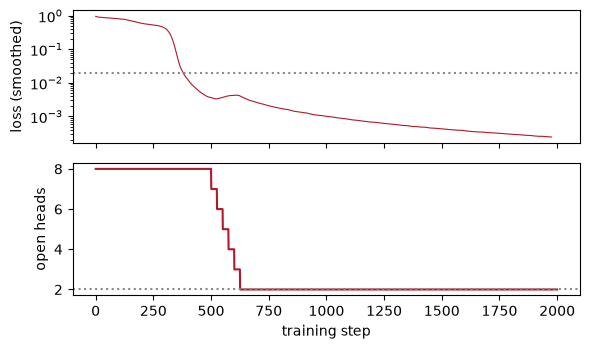

In [56]:
model_hd, valves_hd, log_hd = train(HEADS, rule=True, seed=0)
ok_hd, smooth_hd = never_broke(log_hd)
print(f"heads left: {int((valves_hd > 0).sum())} of {HEADS} (the task needs {R}).  Never broke: {ok_hd}")
fig, ax = plt.subplots(2, 1, figsize=(6, 3.6), sharex=True)
ax[0].semilogy(smooth_hd, color="#b2182b", lw=0.8); ax[0].axhline(0.02, color="#888", ls=":")
ax[0].set_ylabel("loss (smoothed)")
ax[1].plot([h for _, h in log_hd], color="#b2182b"); ax[1].axhline(R, color="#888", ls=":")
ax[1].set_ylabel("open heads"); ax[1].set_xlabel("training step")
plt.tight_layout(); plt.show()

## F.4 The controls: remove one part of the rule at a time

* **No fade**: close heads at once.
* **No re-fit**: value heads without re-fitting (Optimal Brain Damage).
* **No score**: same timing, but close a random head.

Watch which result each one loses: the right count, or never breaking. (One seed each here. The thesis
uses 30 runs per method.)

In [57]:
for name, kwargs in [("full rule", {}), ("no fade", dict(fade=0)), ("no re-fit", dict(score="ablate")),
                     ("no score (random)", dict(score="random"))]:
    _, valves_c, log_c = train(HEADS, rule=True, seed=0, **kwargs)
    ok_c, smooth_c = never_broke(log_c)
    first = np.argmax(smooth_c < 0.02)
    print(f"{name:<18} heads left {int((valves_c > 0).sum())} (needs {R})   never broke: {str(ok_c):<5}   "
          f"worst smoothed loss after solving {smooth_c[first:].max():.4f}")

full rule          heads left 2 (needs 2)   never broke: True    worst smoothed loss after solving 0.0198


no fade            heads left 2 (needs 2)   never broke: False   worst smoothed loss after solving 0.0500


no re-fit          heads left 4 (needs 2)   never broke: True    worst smoothed loss after solving 0.0198


no score (random)  heads left 2 (needs 2)   never broke: False   worst smoothed loss after solving 0.3752


## F.5 The price does not set the size

A needed head is worth about $L_\text{triv}/R$ (here 0.5) and a redundant head about 0. **Any price in
that gap gives the same answer**, so the size comes from the task, not from the price. The thesis tested
prices from 0.01 to 0.1 and got the exact count every time.

In [58]:
for price in (0.01, 0.1):
    _, valves_p, log_p = train(HEADS, rule=True, price=price, seed=0)
    print(f"price {price}: heads left {int((valves_p > 0).sum())} (needs {R})")

price 0.01: heads left 2 (needs 2)


price 0.1: heads left 2 (needs 2)


In [59]:
max_price = None         # by hand: roughly the highest price that still keeps all R = 4 needed heads (in units of L_triv)
check("price ceiling for R = 4", max_price, 1 / 4, tol=0.05)

[ ] price ceiling for R = 4: work it out by hand, replace None with your answer, and run again


---
# Part G. Backup heads when heads can fail

If each head fails at random with probability $p$, keeping a spare is worth it only if it is likely to
be needed. A head contributes ($1/R$ of $L_\text{triv}$) only when it works **and** fewer than $R$ of the
other $B - 1$ heads work:

$$v(B) = \frac{1-p}{R}\; \Pr\big[\text{Binomial}(B-1,\, 1-p) \le R-1\big].$$

The rule keeps the largest $B$ with $v(B)$ at least the price. This was written down before the
experiments and matched 21 of 24 runs exactly.

**By hand** ($R = 2$, $p = 0.1$): $v(2) = 0.45 \times 1 = 0.45$. For $v(3)$, the other 2 heads must not
both work: $\Pr = 1 - 0.9^2 = 0.19$, so $v(3) = 0.45 \times 0.19$.

In [60]:
def v_backup(B, R_, p):
    prob = sum(math.comb(B - 1, j) * (1 - p) ** j * p ** (B - 1 - j) for j in range(R_))   # P[Bin(B-1,1-p) <= R-1]
    return (1 - p) / R_ * prob

def predicted_heads(R_, p, price=0.03):
    B = R_
    while v_backup(B + 1, R_, p) >= price:
        B += 1
    return B

my_v3 = None             # by hand: v(3) for R = 2, p = 0.1
check("v(3)", my_v3, v_backup(3, 2, 0.1))
for R_, p in [(2, 0.1), (4, 0.1), (4, 0.3)]:
    print(f"R = {R_}, p = {p}: keep {predicted_heads(R_, p)} heads")

[ ] v(3): work it out by hand, replace None with your answer, and run again
R = 2, p = 0.1: keep 3 heads
R = 4, p = 0.1: keep 5 heads
R = 4, p = 0.3: keep 7 heads


**Check the formula by simulation.** Fail heads at random many times and measure how much one head adds.

In [61]:
rng = np.random.default_rng(0)
R_, p, B = 2, 0.1, 3
works = rng.random((200000, B)) > p
cover = lambda n_working: np.minimum(n_working, R_) / R_
gain = cover(works.sum(1)) - cover(works[:, 1:].sum(1))          # what head 0 adds
print(f"simulated value of a head {gain.mean():.4f}   formula {v_backup(B, R_, p):.4f}")

simulated value of a head 0.0860   formula 0.0855


---
# Part H. Induction: a circuit that needs two layers

## H.1 The task, by hand

A random sequence contains a chunk of 8 tokens, then a random gap, then the same chunk again. On the
repeat, the model must predict each next token: **after token X came Y last time, so predict Y.**

It takes two steps, one per layer:
1. **Layer 1, previous-token head:** every token records what came before it.
2. **Layer 2, induction head:** at the current token X, find the earlier token whose note says "before
   me was X", and copy it.

One layer cannot do it, whatever its number of heads, because the note has to exist before it can be
searched. The random gap stops the model cheating by position.

In [62]:
from dataclasses import replace
from hemo.induction import ICfg, InductionNet, make_batch as induction_batch, predict_mask, train as induction_train
cfg = ICfg()
tok, starts = induction_batch(1, cfg, torch.Generator().manual_seed(7))
f0, s0 = int(starts[0, 0]), int(starts[0, 1])
print("sequence:", tok[0, :s0 + cfg.L].tolist())
print(f"the chunk starts at position {f0} and repeats at position {s0}")
t_ask = s0 + 2
print(f"Question: on the repeat, the token at position {t_ask} is {int(tok[0, t_ask])}. What comes next?")

sequence: [36, 57, 48, 52, 49, 17, 50, 54, 19, 63, 29, 39, 30, 62, 21, 4, 43, 13, 22, 43, 53, 13, 43, 31, 49, 17, 50, 54, 19, 63, 29, 39]
the chunk starts at position 4 and repeats at position 24
Question: on the repeat, the token at position 26 is 50. What comes next?


In [63]:
my_next = None           # by hand: find the earlier copy of that token, and read the token after it
check("next token", my_next, int(tok[0, t_ask + 1]))

[ ] next token: work it out by hand, replace None with your answer, and run again


## H.2 Train it: one layer against two

Uses the project's own induction code. On a GPU each run takes under a minute; on a laptop CPU a few
minutes. Change `STEPS` to 1500 for a quicker but rougher run.

In [64]:
STEPS = 3000
results_ind = {}
for name, h1, h2 in [("1 layer, 8 heads", 8, 0), ("2 layers, 1 + 1 heads", 1, 1)]:
    c = replace(ICfg(), rule="dense", heads1=h1, heads2=h2, steps=STEPS, seed=0)
    net, out = induction_train(c)
    results_ind[name] = (net, c)
    print(f"{name:<22} next-token accuracy on the repeat {100 * out['final_acc']:.1f}%   loss {out['final_loss']:.3f}")

1 layer, 8 heads       next-token accuracy on the repeat 15.7%   loss 2.532


2 layers, 1 + 1 heads  next-token accuracy on the repeat 99.8%   loss 0.008


## H.3 Look inside the 1 + 1 model

Each plot shows, for every token (row), where it looks (column). Layer 1 should look **one step back**
(a diagonal just below the main one). Layer 2, on the repeat, should look at the token **after the
earlier copy**.

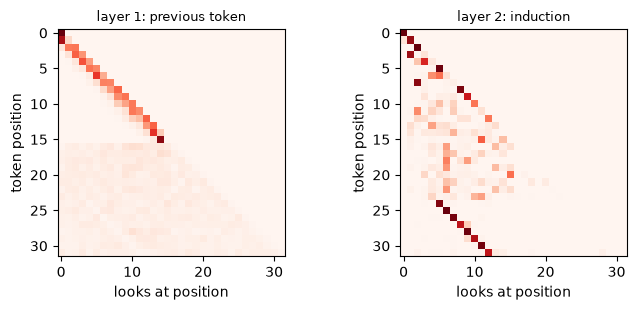

In [65]:
net, c = results_ind["2 layers, 1 + 1 heads"]
net = net.cpu().eval()
tok, starts = induction_batch(1, c, torch.Generator().manual_seed(7))
with torch.no_grad():
    _, attns = net.residual(tok, keep_attn=True)
end = int(starts[0, 1]) + c.L
fig, axs = plt.subplots(1, 2, figsize=(7, 3.2))
for ax_, a_, name in zip(axs, attns, ["layer 1: previous token", "layer 2: induction"]):
    ax_.imshow(a_[0, 0, :end, :end].numpy(), cmap="Reds", vmin=0, vmax=1)
    ax_.set_title(name, fontsize=9); ax_.set_xlabel("looks at position"); ax_.set_ylabel("token position")
plt.tight_layout(); plt.show()

## H.4 "Solved" for a classification task: McFadden's pseudo R squared

Induction is classification (pick the next token out of 64), so it uses the classification form of
$R^2$: $1 - \text{loss}/\text{loss of random guessing}$, with random guessing costing $\ln 64 = 4.16$.
Solved means at least 0.98, about 99% of predictions right.

In [66]:
my_pseudo_r2 = None      # by hand: pseudo R^2 for a loss of 0.05
check("pseudo R^2", my_pseudo_r2, 1 - 0.05 / math.log(64))

[ ] pseudo R^2: work it out by hand, replace None with your answer, and run again


## H.5 The real result

From the experiments: models trained from scratch with only the heads shown (10 runs each), and what
hemodynamic attenuation kept from 8 + 8.

In [67]:
runs_ind = [pickle.load(open(p_, "rb")) for p_ in glob.glob(os.path.join(ROOT, "results", "induction", "*st6000*.pkl"))]
for h in [(1, 0), (8, 0), (1, 1), (2, 1)]:
    rs = [r for r in runs_ind if r["cfg"]["rule"] == "dense" and tuple(r["sizes"]) == h]
    if rs:
        print(f"trained with {h[0]} + {h[1]} heads: solved {sum(r['final_loss'] <= r['bar'] for r in rs)}/{len(rs)}")
ours = [r for r in runs_ind if r["cfg"]["rule"] == "collateral" and r["cfg"].get("probe") == "logit"
        and r["cfg"]["price_frac"] == 0.05 and r["cfg"].get("trial", 0) == 0 and r["cfg"].get("squeeze_at", 0) == 0]
kept = sorted((int(r["kept"][:8].sum()), int(r["kept"][8:].sum())) for r in ours)
print(f"hemodynamic attenuation from 8 + 8 kept: {kept}")
print("Layer 2 reaches the single head it needs. Layer 1 keeps two weak previous-token heads, each doing about half")
print("the job, because closing either would break the model while the other sharpened.")

trained with 1 + 0 heads: solved 0/10
trained with 8 + 0 heads: solved 0/10
trained with 1 + 1 heads: solved 10/10
trained with 2 + 1 heads: solved 10/10
hemodynamic attenuation from 8 + 8 kept: [(2, 1), (2, 1), (2, 1), (2, 1), (2, 1), (2, 1), (2, 1), (2, 1), (2, 1), (2, 1)]
Layer 2 reaches the single head it needs. Layer 1 keeps two weak previous-token heads, each doing about half
the job, because closing either would break the model while the other sharpened.


---
# Part I. Project 3A: transit time and blood pressure

## I.1 Wave speed (Moens-Korteweg)

The pressure wave travels along the artery wall at $\mathrm{PWV} = \sqrt{E h / (\rho d)}$: $E$ wall
stiffness, $h$ wall thickness, $\rho$ blood density, $d$ diameter. Stiffer walls carry faster waves.

**By hand.** $E = 500$ kPa, $h = 1$ mm, $d = 20$ mm, $\rho = 1050$ kg/m^3. (Work in metres and pascals.)

In [68]:
E, h_wall, d_vessel, rho = 500e3, 1e-3, 20e-3, 1050
pwv = math.sqrt(E * h_wall / (rho * d_vessel))
my_pwv = None            # m/s
check("PWV", my_pwv, pwv)

[ ] PWV: work it out by hand, replace None with your answer, and run again


## I.2 From wave speed to pressure

The wall stiffens with pressure, $E = E_0 e^{\zeta P}$, which gives
$P = \frac{2}{\zeta} \ln \mathrm{PWV} + \text{constant}$. The constant differs between people, which
is why transit-time methods need calibration. **Changes** in pressure follow from **ratios** of speed:
$\Delta P = \frac{2}{\zeta} \ln(\mathrm{PWV}_2 / \mathrm{PWV}_1)$.

**By hand.** With $\zeta = 0.017$ per mmHg, how much does pressure rise when PWV rises by 10%?

In [69]:
zeta = 0.017
my_dP = None             # mmHg
check("pressure rise for 10% faster waves", my_dP, 2 / zeta * math.log(1.1), tol=0.05)

[ ] pressure rise for 10% faster waves: work it out by hand, replace None with your answer, and run again


## I.3 Arrival time is not transit time

Most systems time from the ECG R-peak to the pulse at a finger: $\mathrm{PAT} = \mathrm{PEP} + \mathrm{PTT}$.
The pre-ejection period (PEP) changes with how hard the heart contracts, not with pressure. Measuring
at **two sites** cancels it: $\mathrm{PAT}_2 - \mathrm{PAT}_1 = (d_2 - d_1)/\mathrm{PWV}$.

**By hand.** PEP = 80 ms, wrist 0.6 m and finger 0.8 m from the heart, true PWV 8 m/s. Find both arrival
times, then recover PWV from their difference without knowing PEP.

In [70]:
PEP, d1, d2, true_pwv = 0.080, 0.6, 0.8, 8.0
pat1, pat2 = PEP + d1 / true_pwv, PEP + d2 / true_pwv
print(f"PAT wrist {1000 * pat1:.0f} ms, PAT finger {1000 * pat2:.0f} ms")
my_recovered_pwv = None  # m/s, from (d2 - d1) / (PAT2 - PAT1)
check("PWV from two sites", my_recovered_pwv, (d2 - d1) / (pat2 - pat1))

PAT wrist 155 ms, PAT finger 180 ms
[ ] PWV from two sites: work it out by hand, replace None with your answer, and run again


## I.4 Why accuracy cannot certify the mechanism

Two estimators can have the same error on a dataset and compute different things: one uses transit
time, the other a confound (PEP, age, waveform shape) that happens to track pressure in that dataset.
They differ only when conditions change, which is when it matters. So the audit **intervenes**: remove
the transit-time direction inside the model, swap in activations from an input with a different
transit time, or delay the distal pulse, and check the prediction moves the way the physics says. A
small model (Part F) makes that audit practical: fewer heads to check.

---
# Part J. The real results

These are the thesis figures, drawn from the experiment results in `results/`.

fig_setup.png


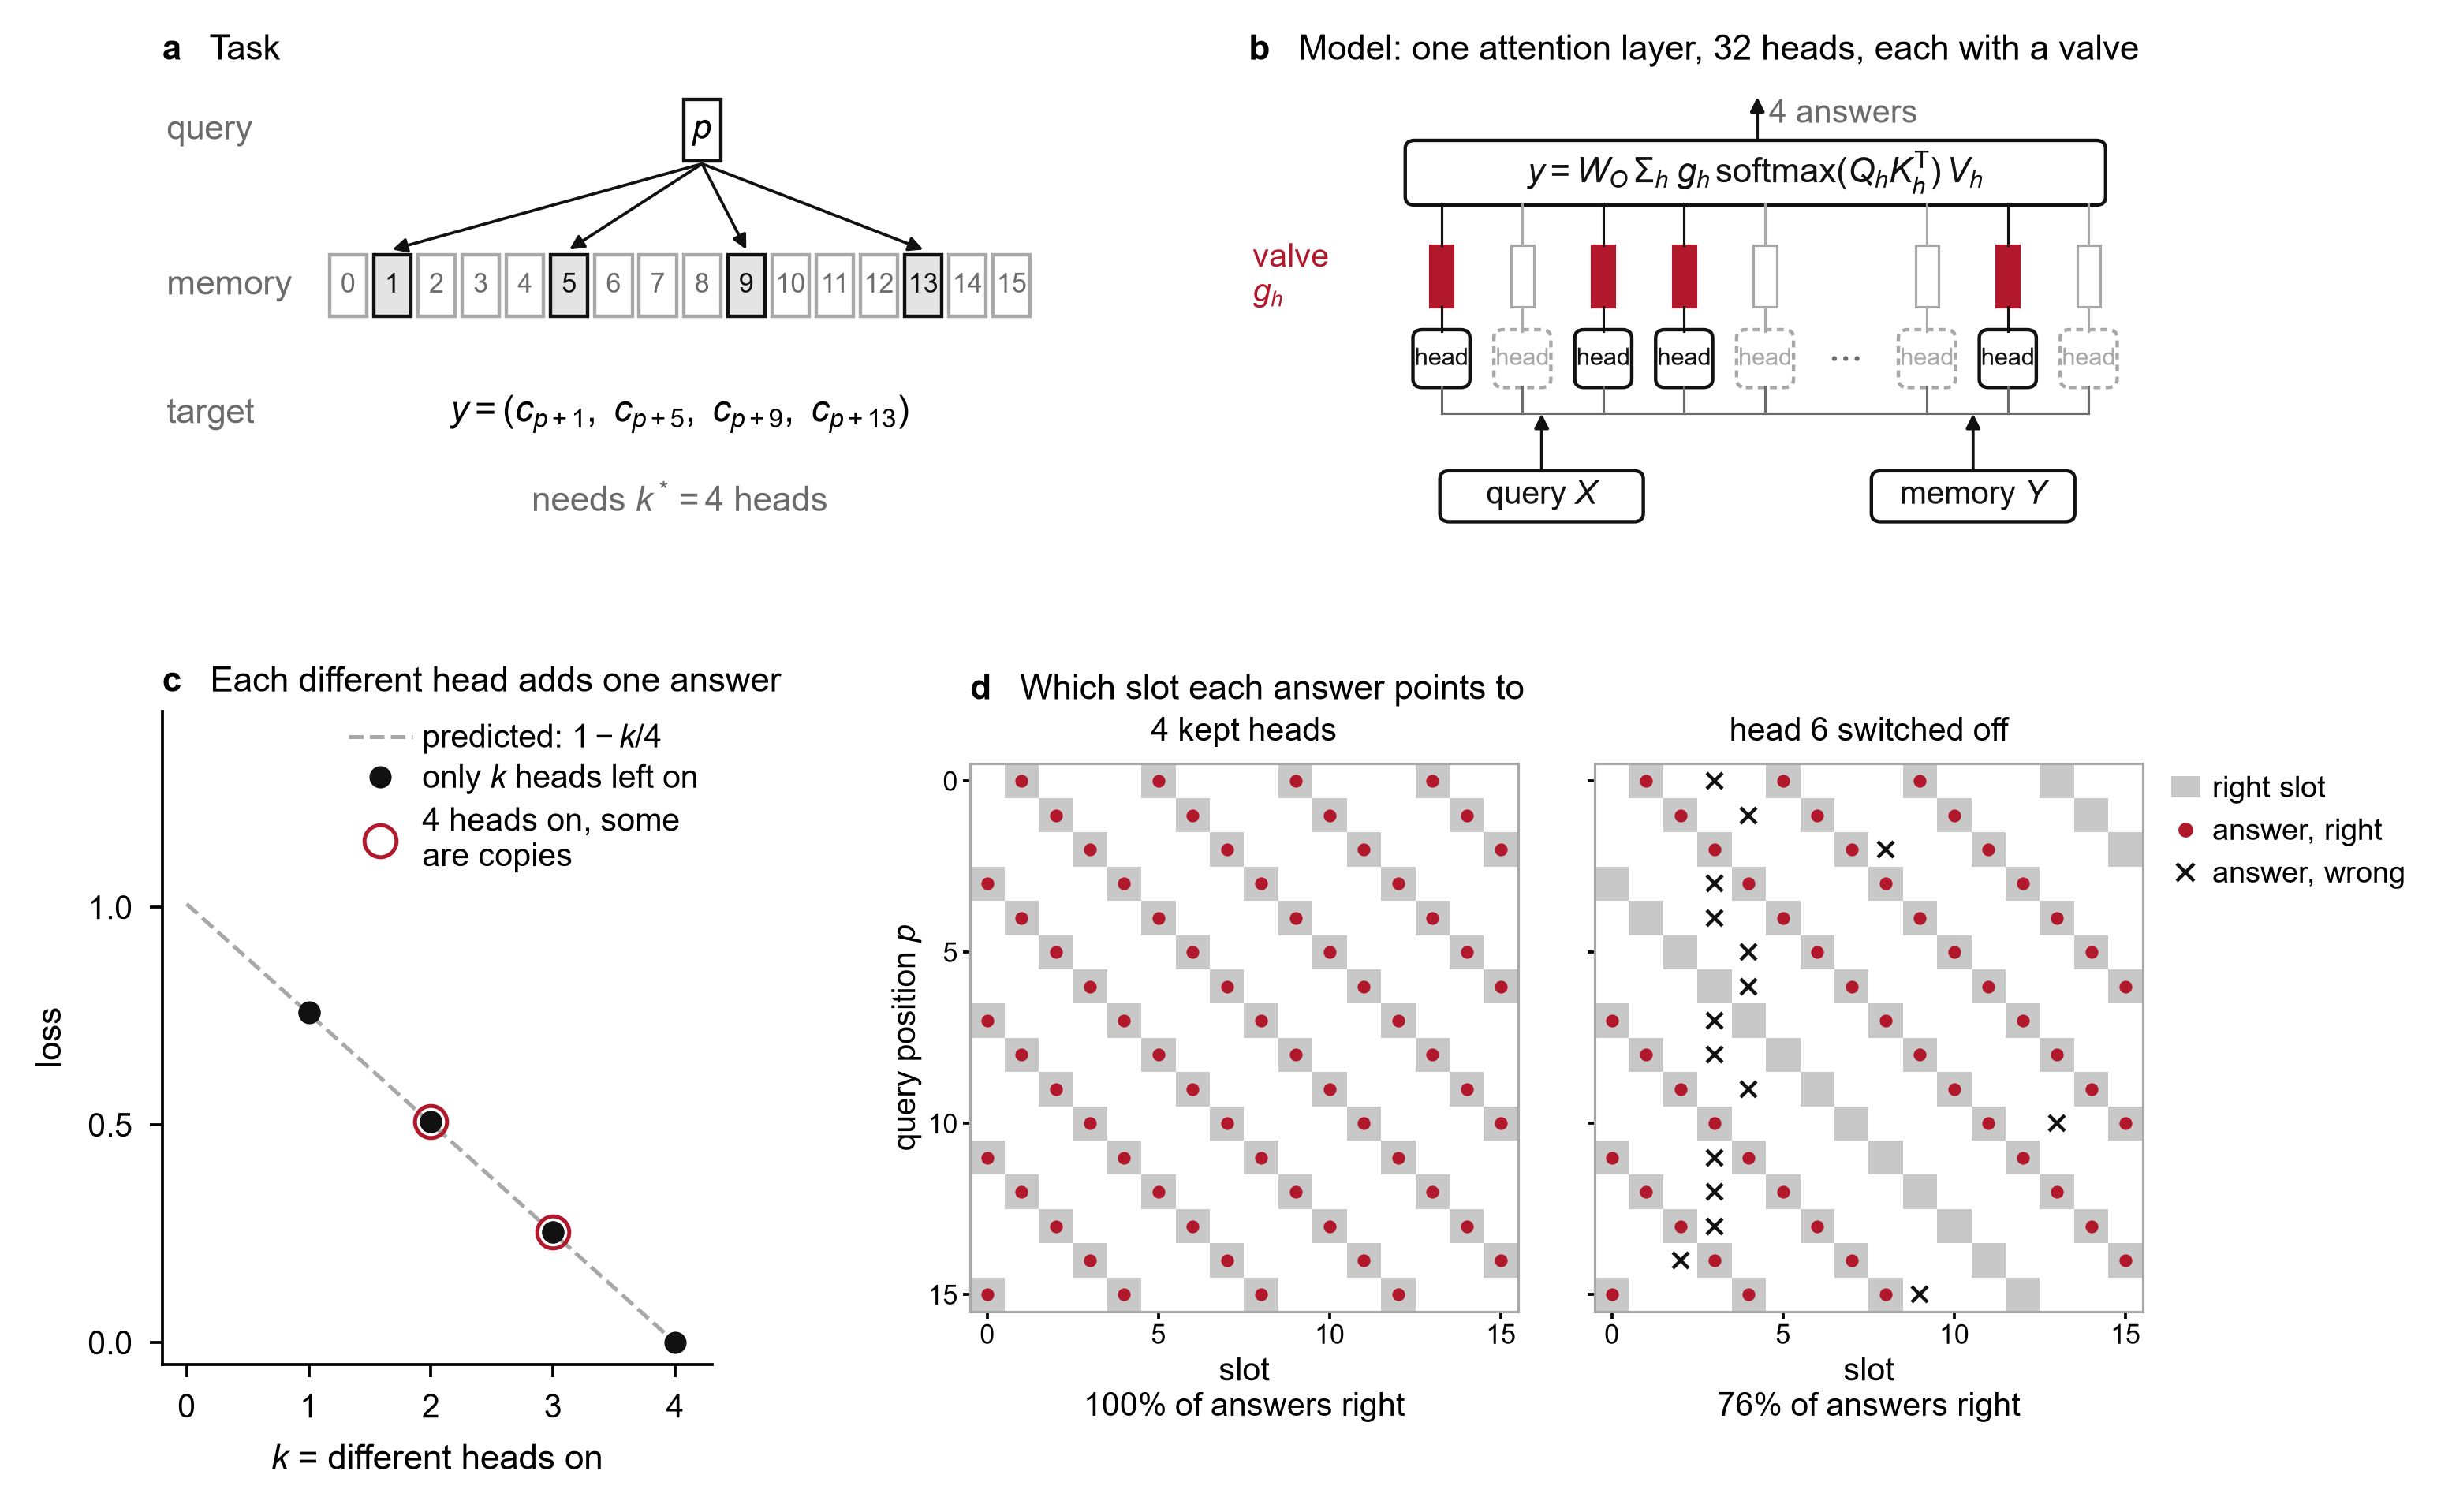

fig_main.png


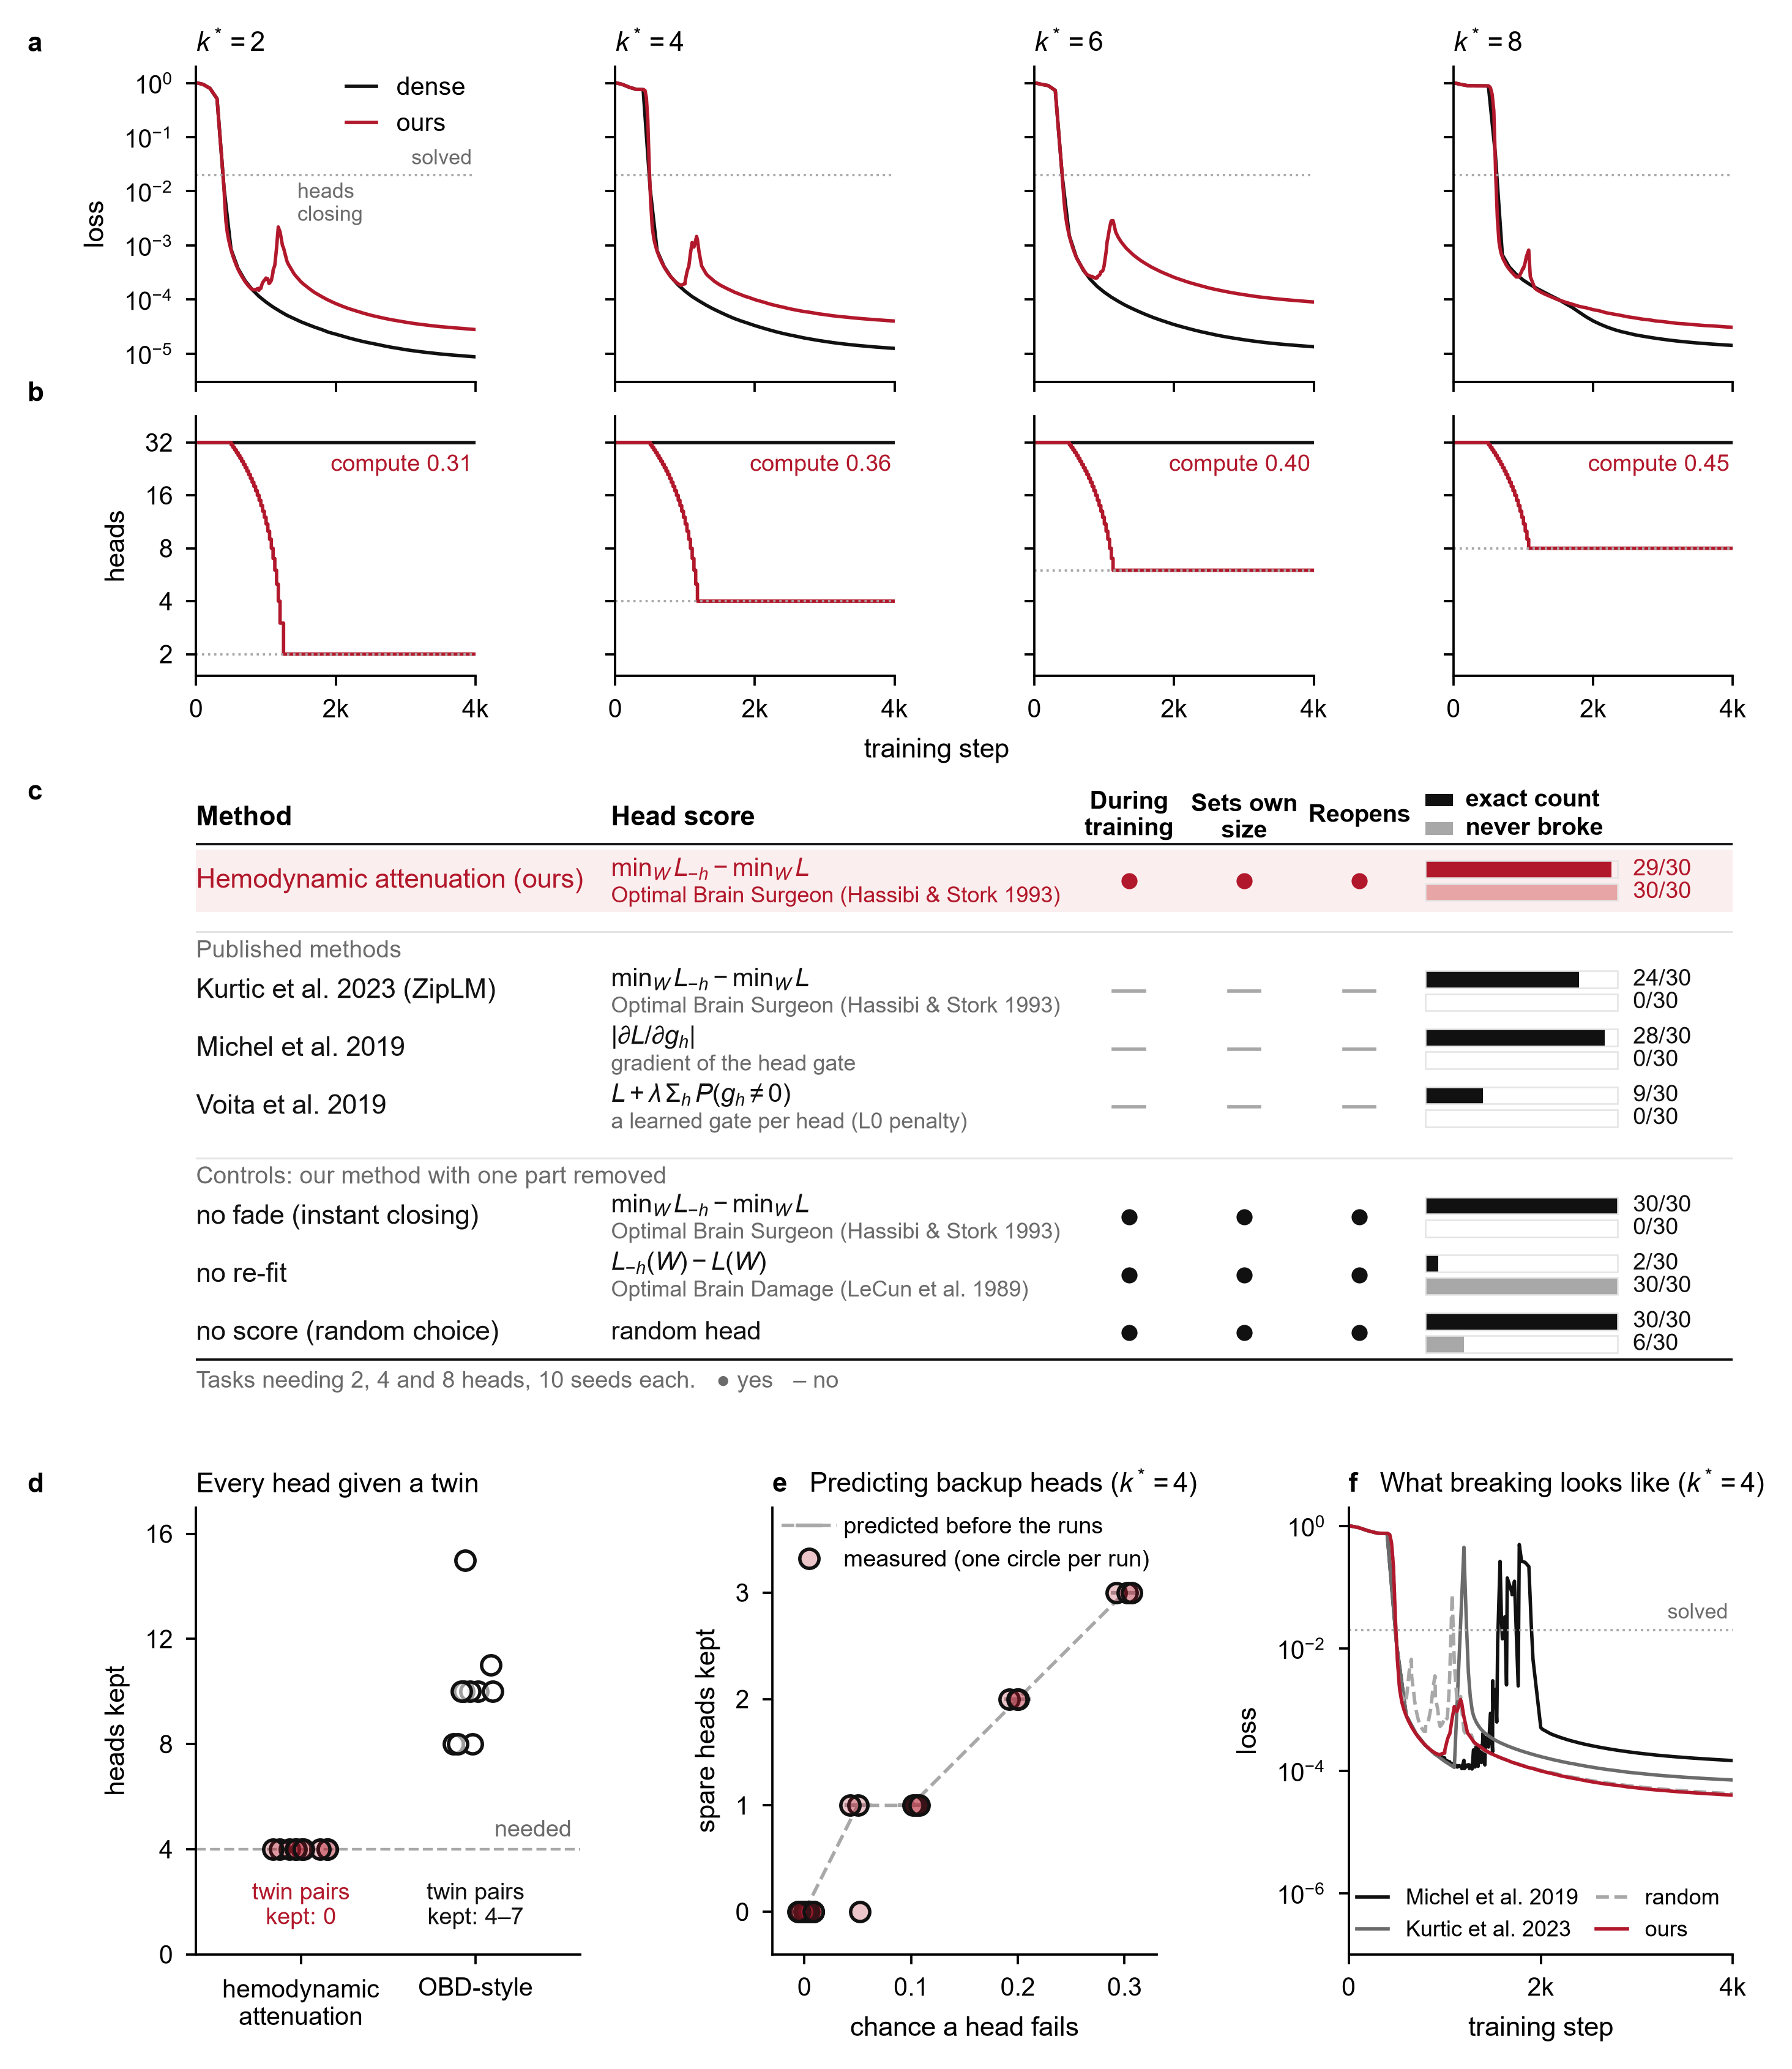

fig_induction.png


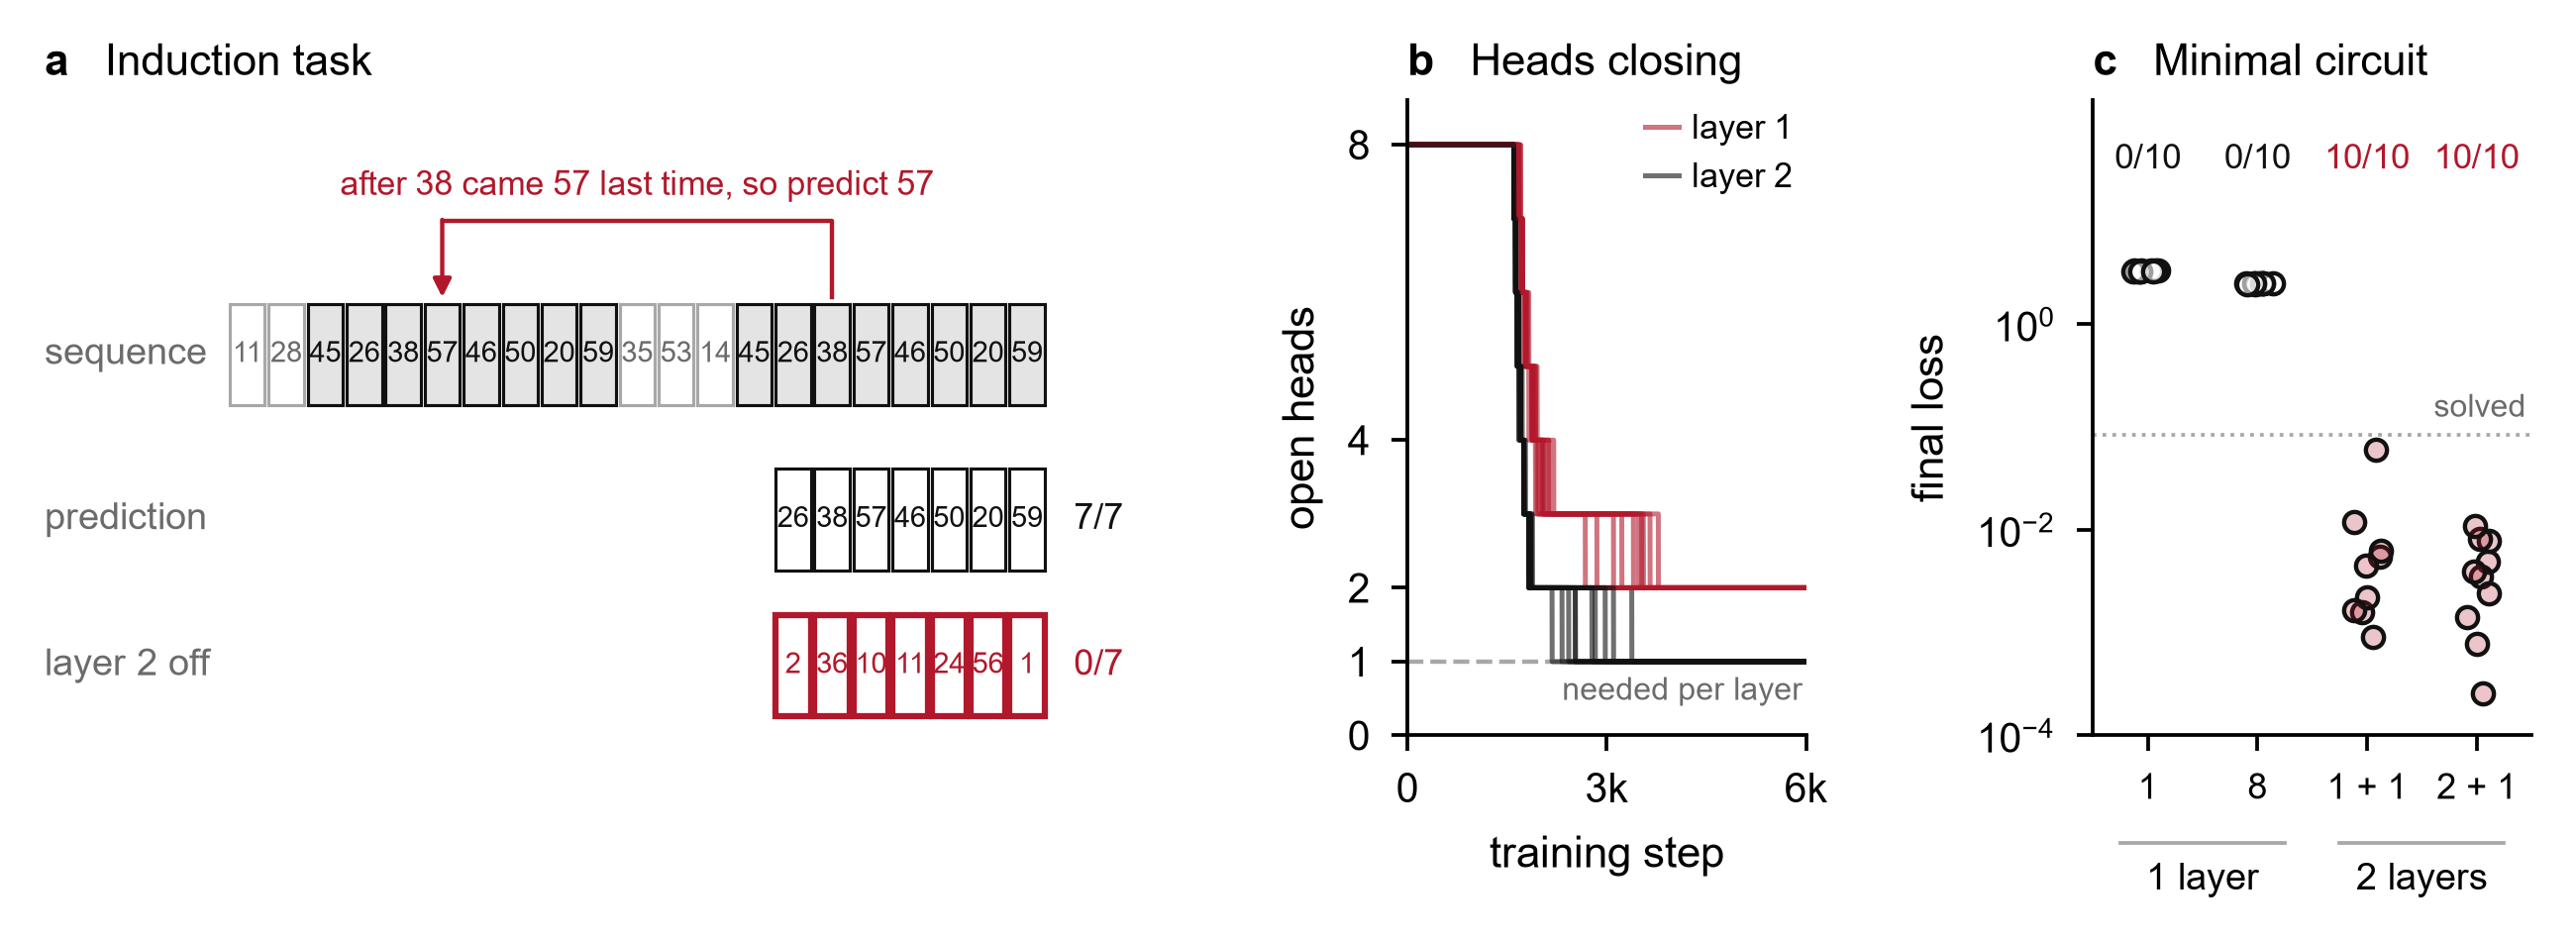

In [71]:
from IPython.display import Image, display
for name in ["fig_setup.png", "fig_main.png", "fig_induction.png"]:
    path = os.path.join(ROOT, "figures", name)
    if os.path.exists(path):
        print(name); display(Image(filename=path, width=900))

**The numbers to remember.**

| | Exact count | Never broke |
|---|---|---|
| Hemodynamic attenuation | 29/30 | 30/30 |
| ZipLM-style (same score, once, after training) | 24/30 | 0/30 |
| Michel et al. (stops when the loss crosses the bar) | 28/30 | 0/30 |
| Michel et al., told the true count | 30/30 | 2/30 |
| Voita et al. (learned gates) | 9/30 | 0/30 |
| No fade | 30/30 | 0/30 |
| No re-fit | 2/30 | 30/30 |
| No score (random head) | 30/30 | 6/30 |

* Any price from 0.01 to 0.1 gave the exact count.
* Duplicated heads: kept 4 heads and never both twins (without re-fit: 8 to 15 heads, 4 to 7 pairs).
* Backup heads: the formula of Part G matched 21 of 24 runs exactly, the rest within one head.
* Induction: kept 2 + 1 (minimum 1 + 1), never broke, kept heads do the right jobs.
* Compute: 0.31 to 0.45 of the dense model's head-steps on paper (closed heads are still computed).

---
# Part K. Questions to expect

**What is the question of the project?** Can a transformer find how many attention heads it needs
while it trains, without being told the number, and without breaking along the way?

**Why this task?** Its answer is known exactly: a counting argument (one head, one equation) says it
needs $R$ heads, and experiments confirm the loss law $(1 - k/R)\,L_\text{triv}$ to within 1%.

**Is the score new?** No. It is the Optimal Brain Surgeon score (Hassibi and Stork 1993), applied to
heads as in ZipLM (2023). What is new is using it during training, with a price instead of a target
size, a gradual fade, and reopening.

**What does each part of the rule do?** The price on the collateral value sets the count (without the
re-fit, the count is wrong: 2/30). Closing the cheapest head, gradually, keeps the model working
(random choice breaks it in 24/30 runs, instant closing in 30/30).

**Isn't the price just a target in disguise?** No. Every price from 0.01 to 0.1 gave the same count,
because a needed head is worth at least $L_\text{triv}/R$ and a redundant one about zero.

**Why does "never broke" matter if the broken models recover?** It shows the rule knows a head's value
before closing it, instead of finding out by damaging the model. It matters for models that are used
while they learn (a wearable estimating blood pressure), and recovery is not guaranteed (learned gates
with a strong penalty removed needed heads and mostly never recovered). On these tasks the final
accuracy of models that recover is similar, and the thesis says so.

**Michel et al. breaks by design, so is the comparison fair?** Its stopping rule crosses the bar. Told
the true count instead, it still broke the model in 28 of 30 runs.

**Why does induction keep 2 + 1 instead of 1 + 1?** The two layer-1 heads each learned a weak version
of the previous-token job (each alone gives 86 to 88% correct, together 99.9%). Closing either costs more
than the price, so the rule refuses to break the model. A layer-wise value, the proposed extension,
targets this.

**Does it scale?** The value needs one inverse per layer. Large models would use a layer-by-layer
approximation, as SparseGPT and ZipLM do. The diagonal shortcut (Optimal Brain Damage) loses the overlap
between heads and fails on copies (B.8). Scaling to GPT-2 small, which has a known circuit, is planned.

**Why cross-attention, and why no MLP?** The questions read a separate memory, which is the
retrieval setting, and without an MLP every computation goes through the heads, so counting heads
counts the circuit.

**What does "solved" mean?** $R^2 \ge 0.98$ for the retrieval task, McFadden's pseudo $R^2 \ge 0.98$
for induction (about 99% correct). Results are the same for any bar from 0.01 to 0.1.

**What is the link to the brain?** Supply follows need (astrocytes), collateral vessels make a vessel
dispensable, vessels cost energy to keep, and unneeded vessels regress gradually. Kozachkov et al. showed
the astrocyte can compute the softmax denominator, a single gain on a block of synapses, and the valve
is the same kind of object for a whole head. The biology motivates the design and is not evidence for it.

**How do Projects 3A and 3B connect?** 3A uses the physics of the large arteries to verify a model
(does it really use transit time?). 3B uses the regulation of the microcirculation to build a model small
enough to verify. The joint experiment trains a blood pressure model with hemodynamic attenuation and
audits the few heads that remain.

**What would make you change your mind?** If, on real models, head values do not separate into needed
and redundant (no gap), the price becomes a size-versus-accuracy dial rather than a way to find one true
size. That is a thesis question, measured in Chapter 4 models and GPT-2 small.